# Meridian Components — Atrasos de fornecedores
## O que está acontecendo, quem está por trás e o que fazer

**A pergunta:** quão sério é o problema dos atrasos de entrega, quais fornecedores merecem atenção primeiro e o que conseguimos, de fato, medir sobre o impacto no negócio?
**Dados:** Kaggle, *Supply Chain Dataset* (dados sintéticos de 2024–2025). **Ferramentas:** Python · Google Colab.

> **Como executar:** `Ambiente de execução → Executar tudo`. A célula de carregamento baixa os CSVs via `kagglehub`; se falhar, pede o upload dos 11 CSVs (ou de um `.zip`). Nenhuma instalação extra é necessária no Colab.
> Este caderno complementa o notebook principal do case (`Case_Meridian_Supply_Chain.ipynb`) e usa as mesmas definições de métricas.

**Como ler este caderno.** Cada capítulo começa com uma pergunta simples, mostra um gráfico e termina com uma frase-resumo (**Em uma frase**). Os detalhes estatísticos ficam em caixas **🔧 Nota técnica**, que você pode abrir se quiser conferir o método.

| Selo | O que significa |
|---|---|
| ✅ **Fato** | medido diretamente nos dados |
| 🔗 **Associação** | duas coisas aparecem juntas, mas isso **não prova** que uma causa a outra |
| 💡 **Hipótese** | explicação plausível que os dados **não conseguem confirmar** |

## Roteiro: uma pergunta por capítulo

| Cap. | Pergunta |
|---|---|
| 0 | Dá para confiar nos dados? |
| 1 | O problema é grande? |
| 2 | Quem atrasa? |
| 3 | Existe algum padrão (país, tipo de fornecedor, época do ano)? |
| 4 | O que está por trás dos atrasos? |
| 5 | Isso custa caro para o negócio? |
| 6 | Os casos extremos são erro ou realidade? |
| 7 | Quais fornecedores são de maior risco? |
| 8 | Dá para prever um atraso antes de ele acontecer? |
| 9 | O que a empresa deveria fazer primeiro? |

## Biblioteca de análise e configuração

As funções de auditoria, métricas, classificação de risco, clustering e modelos ficam em uma única célula abaixo. O **app Streamlit usa exatamente o mesmo código**, o que garante coerência entre notebook e dashboard.

In [1]:
# -*- coding: utf-8 -*-
"""Biblioteca de análise de atrasos de fornecedores (Meridian Components).

Usada pelo notebook `Case_Meridian_Atrasos_Fornecedores.ipynb` (o código é copiado para uma célula)
e pelo app Streamlit (`import atrasos_lib`). Assim os dois calculam exatamente a mesma coisa.
"""
import os
import warnings

import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")

NOMES = ["carrier", "customer", "inventory_snapshot", "product", "production_run", "purchase_order",
         "purchase_order_line", "shipment", "shipment_line", "supplier", "warehouse"]
DATAS = {"purchase_order": ["order_date", "promised_date", "actual_delivery_date"],
         "shipment": ["ship_date", "delivery_date"], "inventory_snapshot": ["snapshot_date"],
         "production_run": ["run_date"]}
LIM_GRAVE = 4          # dias: atraso >= 4 é "grave" (quebra de patamar na distribuição, ver notebook)
SEED = 42


# ----------------------------------------------------------------------------------------------
# Carregamento
# ----------------------------------------------------------------------------------------------
def _completo(p):
    return p is not None and all(os.path.exists(os.path.join(p, n + ".csv")) for n in NOMES)


def localizar_dados():
    """CASE_DATA_DIR -> kagglehub -> pastas locais. (O upload manual no Colab é feito no notebook.)"""
    p = os.environ.get("CASE_DATA_DIR")
    if _completo(p):
        return p
    try:
        import kagglehub
        p = kagglehub.dataset_download("nadhirmazariboufares/supply-chain-dataset")
        if _completo(p):
            return p
    except Exception as e:  # noqa: BLE001
        print("kagglehub indisponível:", type(e).__name__)
    for p in ["data", ".", "/content/data", "/content", "data_upload"]:
        if _completo(p):
            return p
    raise FileNotFoundError("Não encontrei os 11 CSVs (defina CASE_DATA_DIR ou use o upload manual).")


def carregar_brutos(pasta):
    """Lê os CSVs SEM nenhuma conversão (a base original fica preservada)."""
    return {n: pd.read_csv(os.path.join(pasta, n + ".csv")) for n in NOMES}


def tratar(brutos):
    """Cópia tratada: só converte tipos (datas). Nenhum registro é removido aqui."""
    T = {n: df.copy() for n, df in brutos.items()}
    for n, cols in DATAS.items():
        for c in cols:
            T[n][c] = pd.to_datetime(T[n][c], errors="coerce")
    for n in ("supplier", "product", "purchase_order"):
        for c in T[n].select_dtypes(include=["object", "string"]).columns:
            T[n][c] = T[n][c].astype(str).str.strip()
    return T


# ----------------------------------------------------------------------------------------------
# Base analítica de pedidos (1 linha por pedido)
# ----------------------------------------------------------------------------------------------
def classe_entrega(a):
    return pd.Series(np.where(a < 0, "Antecipada", np.where(a == 0, "Pontual", "Atrasada")), index=a.index)


def base_pedidos(T):
    po, pol, sup = T["purchase_order"], T["purchase_order_line"], T["supplier"]
    pol = pol.assign(valor=pol.qty_ordered * pol.unit_cost, gasto=pol.qty_received * pol.unit_cost)
    agg = pol.groupby("po_id").agg(valor=("valor", "sum"), gasto=("gasto", "sum"), itens=("qty_ordered", "sum"),
                                   linhas=("po_line_id", "count"), qtd_rec=("qty_received", "sum"),
                                   qtd_rej=("qty_rejected", "sum")).reset_index()
    p = (po.merge(sup.rename(columns={"supplier_name": "fornecedor", "country": "pais"}), on="supplier_id",
                  how="left", validate="m:1").merge(agg, on="po_id", how="left", validate="1:1"))
    p["entregue"] = p.status.eq("Delivered")
    p["atraso"] = (p.actual_delivery_date - p.promised_date).dt.days.where(p.entregue)
    p["prazo_prometido"] = (p.promised_date - p.order_date).dt.days
    p["classe"] = np.where(p.entregue, classe_entrega(p.atraso.fillna(0)), "Sem entrega")
    p["atrasado"] = (p.atraso > 0).astype(float).where(p.entregue)
    p["grave"] = (p.atraso >= LIM_GRAVE).astype(float).where(p.entregue)
    p["atraso_rel"] = p.atraso / p.prazo_prometido
    p["ano_mes"] = p.order_date.dt.to_period("M").astype(str)
    p["ano"] = p.order_date.dt.year
    p["mes"] = p.order_date.dt.month
    p["dow"] = p.order_date.dt.dayofweek
    return p


# ----------------------------------------------------------------------------------------------
# Auditoria de qualidade
# ----------------------------------------------------------------------------------------------
def auditoria(brutos, T):
    """Tabela do 'Diagnóstico e Qualidade dos Dados'. Tudo calculado nos dados brutos/tratados."""
    bpo, bpol, bsup, bprod = (brutos[k] for k in ("purchase_order", "purchase_order_line", "supplier", "product"))
    po, pol, sup, prod = (T[k] for k in ("purchase_order", "purchase_order_line", "supplier", "product"))
    N = len(po)
    ent = po[po.status.eq("Delivered")]
    atr = (ent.actual_delivery_date - ent.promised_date).dt.days
    lead = po.merge(sup[["supplier_id", "lead_time_days"]], on="supplier_id")
    prazo = (lead.promised_date - lead.order_date).dt.days
    q1, q3 = atr.quantile([.25, .75]); lim_sup = q3 + 1.5 * (q3 - q1)
    cols_data = [c for c in DATAS["purchase_order"]]
    texto = sum(int(bpo[c].map(lambda v: isinstance(v, str)).sum()) for c in cols_data)
    invalidas = sum(int((pd.to_datetime(bpo[c], errors="coerce").isna() & bpo[c].notna()).sum()) for c in cols_data)
    var_nome = 0
    for df, c in [(bsup, "country"), (bsup, "tier"), (bprod, "category"), (bpo, "status")]:
        norm = df[c].astype(str).str.strip().str.casefold()
        var_nome += int((df[c].astype(str) != df[c].astype(str).str.strip()).sum())
        var_nome += int(df.groupby(norm)[c].nunique().gt(1).sum())
    neg = int((pol[["qty_ordered", "qty_received", "qty_rejected", "unit_cost"]] < 0).sum().sum()
              + (sup[["lead_time_days", "payment_terms_days", "min_order_value"]] < 0).sum().sum())
    canc = po[po.status.eq("Cancelled")]
    rows = [
        ("Tipos", "Datas lidas como texto no CSV (3 colunas de purchase_order)", texto, 3 * N,
         "O CSV traz datas como texto; sem conversão, não dá para calcular prazos.",
         "Tratar: converter para datetime na cópia tratada (o original continua intacto).",
         "Habilita todos os cálculos de atraso. Sem efeito sobre os números."),
        ("Datas", "Datas impossíveis de converter", invalidas, 3 * N, "Datas com formato inválido.",
         "Nenhuma ação necessária." if invalidas == 0 else "Tratar separadamente.",
         "Nenhum registro perdido." if invalidas == 0 else "Registros ficariam sem atraso calculável."),
        ("Ausentes", "actual_delivery_date vazio", int(bpo.actual_delivery_date.isna().sum()), N,
         "Pedidos sem data de entrega. Coincidem com os pedidos cancelados.",
         "Tratar separadamente: manter na base, fora das métricas de atraso. Não imputar.",
         "Se contados como 'não atrasados', o % de atraso cairia (ver comparação antes/depois)."),
        ("Ausentes", "Outras colunas de purchase_order / purchase_order_line / supplier com nulos",
         int(bpo.drop(columns="actual_delivery_date").isna().sum().sum() + bpol.isna().sum().sum() + bsup.isna().sum().sum()),
         N, "Campos obrigatórios vazios.", "Nenhuma ação necessária.", "Nenhum."),
        ("Duplicidade", "Linhas duplicadas ou po_id repetido", int(bpo.duplicated().sum() + bpo.po_id.duplicated().sum()), N,
         "Pedidos repetidos inflariam contagens.", "Nenhuma ação necessária.", "Nenhum."),
        ("Datas", "Prazo prometido anterior à data do pedido", int((po.promised_date < po.order_date).sum()), N,
         "Promessa antes do pedido é impossível.", "Nenhuma ação necessária.", "Nenhum."),
        ("Datas", "Entrega real anterior à data do pedido", int((ent.actual_delivery_date < ent.order_date).sum()),
         len(ent), "Entrega antes de pedir é impossível.", "Nenhuma ação necessária.", "Nenhum."),
        ("Datas", "Pedido 'Delivered' sem data de entrega", int((po.status.eq("Delivered") & po.actual_delivery_date.isna()).sum()),
         N, "Entregue sem data impediria medir o atraso.", "Nenhuma ação necessária.", "Nenhum."),
        ("Datas", "Pedido 'Cancelled' com data de entrega", int((canc.actual_delivery_date.notna()).sum()), len(canc),
         "Cancelado que aparece como entregue.", "Nenhuma ação necessária.", "Nenhum."),
        ("Valores", "Valores negativos (quantidades, custo unitário, prazos, mínimos)", neg, len(pol),
         "Quantidades ou custos negativos seriam erro.", "Nenhuma ação necessária.", "Nenhum."),
        ("Valores", "Qtd. recebida > pedida, ou rejeitada > recebida", int((pol.qty_received > pol.qty_ordered).sum()
                                                                          + (pol.qty_rejected > pol.qty_received).sum()),
         len(pol), "Inconsistência de quantidades.", "Nenhuma ação necessária.", "Nenhum."),
        ("Consistência", "Prazo prometido diferente do lead time cadastrado do fornecedor", int((prazo != lead.lead_time_days).sum()),
         N, "A promessa deveria seguir o lead time do cadastro.", "Nenhuma ação necessária (promessa = pedido + lead time).",
         "Confirma que 'prometido' é um prazo contratual, não negociado caso a caso."),
        ("Nomenclatura", "Categorias com grafias diferentes para o mesmo valor (país, tier, categoria, status)", var_nome,
         len(sup) + len(prod) + N, "Variações de caixa/espaços fragmentariam agrupamentos.",
         "Nenhuma ação necessária (espaços removidos por segurança na cópia tratada).", "Nenhum."),
        ("Incompletos", "Pedidos sem nenhuma linha de item", int((~po.po_id.isin(pol.po_id)).sum()), N,
         "Pedido sem itens não tem valor nem quantidade.", "Nenhuma ação necessária.", "Nenhum."),
        ("Incompletos", "Pedidos cancelados com itens recebidos", int(pol[pol.po_id.isin(canc.po_id)].qty_received.gt(0).sum()),
         len(pol), "Cancelado deveria ter recebido zero.", "Nenhuma ação necessária.", "Nenhum."),
        ("Extremos", f"Atraso acima do limite IQR 1,5x (> {lim_sup:.0f} dias)", int((atr > lim_sup).sum()), len(ent),
         "Atrasos longos. São eventos reais concentrados em poucos fornecedores (ver seção de outliers).",
         "Manter e tratar separadamente (comparar com e sem).", "Remover esconderia exatamente o problema que se quer medir."),
        ("Extremos", "Entregas antecipadas (antes do prometido)", int((atr < 0).sum()), len(ent),
         "Entrega adiantada não é erro; é um resultado diferente de pontual.",
         "Manter; classificar à parte (Antecipada / Pontual / Atrasada).",
         "Tratar adiantada como pontual esconderia a variabilidade dos prazos."),
    ]
    a = pd.DataFrame(rows, columns=["categoria", "verificação", "afetados", "base", "problema", "decisão", "impacto da decisão"])
    a["% da base"] = (a.afetados / a.base * 100).round(2)
    a.insert(0, "#", range(1, len(a) + 1))
    return a


def antes_depois(brutos, T, ped):
    """Resumo antes/depois do tratamento: contagens e efeito sobre o indicador principal."""
    bpo = brutos["purchase_order"]
    ent = ped[ped.entregue]
    naive = float((ent.atrasado == 1).sum() / len(bpo))
    return pd.DataFrame([
        ("Pedidos na base", len(bpo), len(ped), "Nenhum pedido removido"),
        ("Colunas de purchase_order", bpo.shape[1], T["purchase_order"].shape[1], "Só conversão de tipo (datas)"),
        ("Datas como texto (colunas)", 3, 0, "Convertidas para datetime"),
        ("Pedidos com atraso calculável", 0, len(ent), "Entregues (cancelados ficam à parte)"),
        ("% de pedidos atrasados (denominador = todos os 3.000)", f"{naive*100:.1f}%", f"{ent.atrasado.mean()*100:.1f}%",
         "Denominador correto = só entregues"),
        ("Atraso médio (dias)", "—", f"{ent.atraso.mean():.2f}", "Só entregues"),
    ], columns=["indicador", "base original", "base tratada", "observação"])


# ----------------------------------------------------------------------------------------------
# Métricas por fornecedor
# ----------------------------------------------------------------------------------------------
def metricas_fornecedor(ped):
    e = ped[ped.entregue].copy()
    g = e.groupby("fornecedor")

    def cond(s):  # severidade condicional: atraso médio SÓ entre as entregas atrasadas
        return s[s > 0].mean() if (s > 0).any() else 0.0

    f = pd.DataFrame({
        "tier": g.tier.first(), "pais": g.pais.first(), "rating": g.quality_rating.first(),
        "single_source": g.is_single_source.first(), "prazo_prometido": g.prazo_prometido.mean(),
        "pedidos": g.size(),
        "pct_antecipado": g.atraso.apply(lambda s: (s < 0).mean()), "pct_pontual": g.atraso.apply(lambda s: (s == 0).mean()),
        "pct_atrasado": g.atraso.apply(lambda s: (s > 0).mean()),
        "atraso_medio": g.atraso.mean(), "atraso_mediano": g.atraso.median(), "desvio": g.atraso.std(),
        "p90": g.atraso.quantile(.9), "maximo": g.atraso.max(), "severidade": g.atraso.apply(cond),
        "dias_atraso_total": g.atraso.apply(lambda s: s.clip(lower=0).sum()),
        "pct_grave": g.atraso.apply(lambda s: (s >= LIM_GRAVE).mean()),
        "gasto": g.gasto.sum(), "pct_expedite": g.expedited.mean(),
    })
    f["cv"] = f.desvio / f.atraso_medio.abs().replace(0, np.nan)
    f["atraso_rel"] = f.atraso_medio / f.prazo_prometido
    f["share_gasto"] = f.gasto / f.gasto.sum()
    f["share_dias_atraso"] = f.dias_atraso_total / f.dias_atraso_total.sum()
    return f.reset_index()


def z_modificado(x):
    """Escore z robusto (Iglewicz & Hoaglin): 0,6745·(x − mediana)/MAD. Limite usual: |z| > 3,5."""
    x = np.asarray(x, float)
    mad = np.median(np.abs(x - np.median(x)))
    return 0.6745 * (x - np.median(x)) / (mad if mad > 0 else np.nan)


def classificar_risco(f, alfa=0.05):
    """Risco de atraso com dois critérios estatísticos (sem cortes arbitrários):
    - GRAVIDADE: severidade (atraso médio entre as entregas atrasadas) com z modificado > 3,5.
    - FREQUÊNCIA: % atrasado acima da mediana dos fornecedores, teste binomial unilateral com correção de Holm.
    Alto = os dois; Intermediário = um dos dois; Baixo = nenhum."""
    f = f.copy()
    f["z_severidade"] = z_modificado(f.severidade)
    f["crit_gravidade"] = f.z_severidade > 3.5
    base = float(f.pct_atrasado.median())
    p = np.array([stats.binomtest(int(round(r.pct_atrasado * r.pedidos)), int(r.pedidos), base, alternative="greater").pvalue
                  for r in f.itertuples()])
    ordem = np.argsort(p); m = len(p); ajust = np.empty(m); run = 0.0
    for rank, i in enumerate(ordem):
        run = max(run, min(1.0, (m - rank) * p[i])); ajust[i] = run
    f["p_frequencia"] = ajust
    f["crit_frequencia"] = f.p_frequencia < alfa
    n = f.crit_gravidade.astype(int) + f.crit_frequencia.astype(int)
    f["risco"] = np.select([n == 2, n == 1], ["Alto", "Intermediário"], "Baixo")
    f.attrs["pct_base_mediana"] = base
    return f


def agrupar(f, k_max=5):
    """K-Means com atributos padronizados. Escolhe k pela silhueta (k=2..k_max). Retorna (f_com_grupo, tabela_k)."""
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    from sklearn.preprocessing import StandardScaler
    cols = ["pct_atrasado", "severidade", "desvio", "p90"]
    X = StandardScaler().fit_transform(f[cols])
    res = []
    for k in range(2, k_max + 1):
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
        res.append((k, km.inertia_, silhouette_score(X, km.labels_)))
    tab = pd.DataFrame(res, columns=["k", "inércia", "silhueta"])
    k = int(tab.loc[tab.silhueta.idxmax(), "k"])
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    f = f.copy(); f["grupo"] = km.labels_
    ordem = f.groupby("grupo").severidade.mean().sort_values(ascending=False).index
    nomes = {g: f"Grupo {i + 1}" for i, g in enumerate(ordem)}
    f["grupo"] = f.grupo.map(nomes)
    return f, tab


# ----------------------------------------------------------------------------------------------
# Outliers
# ----------------------------------------------------------------------------------------------
def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k * i, q3 + k * i


def resumo_outliers(df, colunas):
    out = []
    for nome, col in colunas.items():
        s = df[col].dropna()
        lo, hi = limites_iqr(s); lo3, hi3 = limites_iqr(s, 3)
        z = (s - s.mean()) / s.std()
        out.append({"variável": nome, "n": len(s), "limite inferior (1,5×IQR)": round(lo, 2), "limite superior (1,5×IQR)": round(hi, 2),
                    "outliers 1,5×IQR": int(((s < lo) | (s > hi)).sum()),
                    "% 1,5×IQR": round(((s < lo) | (s > hi)).mean() * 100, 2),
                    "outliers 3×IQR": int(((s < lo3) | (s > hi3)).sum()), "|z| > 3": int((z.abs() > 3).sum()),
                    "P1": round(s.quantile(.01), 2), "P99": round(s.quantile(.99), 2), "máximo": round(s.max(), 2)})
    return pd.DataFrame(out)


def isolation(ped, contaminacao=0.05):
    from sklearn.ensemble import IsolationForest
    from sklearn.preprocessing import StandardScaler
    e = ped[ped.entregue].copy()
    X = StandardScaler().fit_transform(np.c_[e.atraso, e.prazo_prometido, np.log1p(e.valor), np.log1p(e.itens)])
    m = IsolationForest(n_estimators=300, contamination=contaminacao, random_state=SEED).fit(X)
    e["iso_outlier"] = m.predict(X) == -1
    e["iso_score"] = -m.score_samples(X)
    return e


# ----------------------------------------------------------------------------------------------
# Modelos
# ----------------------------------------------------------------------------------------------
NUM_PED = ["expedited", "log_valor", "log_itens", "linhas", "mes", "dow"]
NUM_FORN = ["quality_rating", "payment_terms_days", "min_order_value", "is_single_source", "lead_time_days"]
CAT_FORN = ["pais", "tier"]


def matriz_modelo(ped):
    e = ped[ped.entregue].copy()
    e["log_valor"] = np.log1p(e.valor); e["log_itens"] = np.log1p(e.itens)
    return e.reset_index(drop=True)


def _pipe(modelo, num, cat):
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    pre = ColumnTransformer([("n", StandardScaler(), num)] + ([("c", OneHotEncoder(handle_unknown="ignore"), cat)] if cat else []))
    return Pipeline([("pre", pre), ("m", modelo)])


def modelos_classificacao():
    from sklearn.dummy import DummyClassifier
    from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.tree import DecisionTreeClassifier
    return {"Linha de base (classe majoritária)": DummyClassifier(strategy="prior"),
            "Regressão logística": LogisticRegression(max_iter=2000, C=1.0),
            "Árvore de decisão (prof. 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
            "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=SEED, n_jobs=-1),
            "Gradient Boosting": GradientBoostingClassifier(random_state=SEED)}


def modelos_regressao():
    from sklearn.dummy import DummyRegressor
    from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
    from sklearn.linear_model import LinearRegression
    return {"Linha de base (média do treino)": DummyRegressor(),
            "Regressão linear": LinearRegression(),
            "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=6, random_state=SEED, n_jobs=-1),
            "Gradient Boosting": GradientBoostingRegressor(random_state=SEED)}


def conjuntos_de_atributos():
    return {"Só atributos do pedido": (NUM_PED, []),
            "Pedido + atributos do fornecedor": (NUM_PED + NUM_FORN, CAT_FORN)}


def _metricas_clf(y, p, prob):
    from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
    auc = roc_auc_score(y, prob) if len(np.unique(y)) > 1 else np.nan
    return {"precisão": precision_score(y, p, zero_division=0), "recall": recall_score(y, p, zero_division=0),
            "F1": f1_score(y, p, zero_division=0), "ROC-AUC": auc}


def avaliar_classificacao(e, alvo="grave", cv_rep=None):
    """Três esquemas de validação:
    - 'Temporal': treina em 2024, testa em 2025 (cenário real de uso: prever pedidos futuros de fornecedores conhecidos).
    - 'Aleatória 5-fold': mistura períodos e fornecedores (pode inflar o resultado se o fornecedor 'vaza' pelos atributos).
    - 'Leave-one-supplier-out': testa em fornecedor que o modelo nunca viu (generalização a novos fornecedores)."""
    from sklearn.base import clone
    from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
    y = e[alvo].astype(int).values
    tr, te = (e.ano == 2024).values, (e.ano == 2025).values
    linhas, guarda = [], {}
    for fs, (num, cat) in conjuntos_de_atributos().items():
        X = e[num + cat]
        for nome, mod in modelos_classificacao().items():
            pipe = _pipe(clone(mod), num, cat)
            pipe.fit(X[tr], y[tr]); prob = pipe.predict_proba(X[te])[:, 1]
            linhas.append({"atributos": fs, "modelo": nome, "validação": "Temporal (2024→2025)", **_metricas_clf(y[te], (prob >= .5).astype(int), prob)})
            guarda[(fs, nome)] = (y[te], prob)
            skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
            prob = cross_val_predict(_pipe(clone(mod), num, cat), X, y, cv=skf, method="predict_proba")[:, 1]
            linhas.append({"atributos": fs, "modelo": nome, "validação": "Aleatória (5-fold)", **_metricas_clf(y, (prob >= .5).astype(int), prob)})
            prob = cross_val_predict(_pipe(clone(mod), num, cat), X, y, cv=LeaveOneGroupOut(), groups=e.fornecedor.values,
                                     method="predict_proba")[:, 1]
            m = _metricas_clf(y, (prob >= .5).astype(int), prob)
            m["ROC-AUC"] = np.nan   # AUC agrupada de 20 modelos diferentes não é comparável: omitida de propósito
            linhas.append({"atributos": fs, "modelo": nome, "validação": "Fornecedor novo (leave-one-supplier-out)", **m})
    return pd.DataFrame(linhas), guarda


def avaliar_regressao(e):
    from sklearn.base import clone
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
    y = e.atraso.values.astype(float)
    tr, te = (e.ano == 2024).values, (e.ano == 2025).values
    met = lambda yt, yp: {"MAE": mean_absolute_error(yt, yp), "RMSE": float(np.sqrt(mean_squared_error(yt, yp))), "R²": r2_score(yt, yp)}  # noqa: E731
    linhas = []
    for fs, (num, cat) in conjuntos_de_atributos().items():
        X = e[num + cat]
        for nome, mod in modelos_regressao().items():
            pipe = _pipe(clone(mod), num, cat).fit(X[tr], y[tr])
            linhas.append({"atributos": fs, "modelo": nome, "validação": "Temporal (2024→2025)", **met(y[te], pipe.predict(X[te]))})
            yp = cross_val_predict(_pipe(clone(mod), num, cat), X, y, cv=LeaveOneGroupOut(), groups=e.fornecedor.values)
            linhas.append({"atributos": fs, "modelo": nome, "validação": "Fornecedor novo (leave-one-supplier-out)", **met(y, yp)})
    return pd.DataFrame(linhas)


def importancia_permutacao(e, alvo="grave", n_rep=5):
    from sklearn.ensemble import GradientBoostingClassifier
    from sklearn.inspection import permutation_importance
    num, cat = conjuntos_de_atributos()["Pedido + atributos do fornecedor"]
    y = e[alvo].astype(int).values
    tr, te = (e.ano == 2024).values, (e.ano == 2025).values
    pipe = _pipe(GradientBoostingClassifier(random_state=SEED), num, cat).fit(e.loc[tr, num + cat], y[tr])
    r = permutation_importance(pipe, e.loc[te, num + cat], y[te], scoring="roc_auc", n_repeats=n_rep, random_state=SEED)
    return pd.DataFrame({"atributo": num + cat, "queda_AUC": r.importances_mean, "dp": r.importances_std}).sort_values("queda_AUC", ascending=False)


# ----------------------------------------------------------------------------------------------
# Impacto no estoque / serviço (testes de associação)
# ----------------------------------------------------------------------------------------------
def cobertura_rop(T):
    """ROP expresso em dias de demanda (ROP médio / demanda média diária do par armazém×produto)."""
    sl = T["shipment_line"].merge(T["shipment"][["shipment_id", "warehouse_id", "ship_date"]], on="shipment_id")
    dias = (T["shipment"].ship_date.max() - T["shipment"].ship_date.min()).days + 1
    d = sl.groupby(["warehouse_id", "product_id"]).qty_shipped.sum() / dias
    rop = T["inventory_snapshot"].groupby(["warehouse_id", "product_id"]).reorder_point.mean()
    return (rop / d).dropna()


def painel_produto_mes(T, ped):
    """Painel produto×mês: exposição a entregas graves (mês da entrega) e ruptura/abaixo do ROP no mês seguinte."""
    pol, inv = T["purchase_order_line"], T["inventory_snapshot"]
    L = pol.merge(ped[ped.entregue][["po_id", "atraso", "actual_delivery_date"]], on="po_id")
    L["mes_ent"] = L.actual_delivery_date.dt.to_period("M").astype(str)
    g = L.groupby(["product_id", "mes_ent"]).apply(lambda x: pd.Series({
        "un": x.qty_received.sum(), "un_grave": x.loc[x.atraso >= LIM_GRAVE, "qty_received"].sum(),
        "atraso_pond": np.average(x.atraso, weights=x.qty_received) if x.qty_received.sum() > 0 else np.nan})).reset_index()
    g["sh_grave"] = g.un_grave / g.un
    inv = inv.assign(mes=inv.snapshot_date.dt.to_period("M").astype(str), rup=inv.units_on_hand == 0,
                     abx=inv.units_on_hand < inv.reorder_point)
    iv = inv.groupby(["product_id", "mes"]).agg(rup=("rup", "mean"), abx=("abx", "mean")).reset_index()
    meses = sorted(iv.mes.unique()); prox = {m: meses[i + 1] for i, m in enumerate(meses[:-1])}
    g["mes_prox"] = g.mes_ent.map(prox)
    return g.merge(iv, left_on=["product_id", "mes_prox"], right_on=["product_id", "mes"], how="inner")


def regra_simples(e, alvo="grave"):
    """Referência sem aprendizado de máquina: marca como 'grave' o pedido de todo fornecedor cujo atraso médio de 2024
    é um valor atípico (z modificado > 3,5). Avaliada em 2025."""
    tr, te = e[e.ano == 2024], e[e.ano == 2025]
    m = tr.groupby("fornecedor").atraso.mean()
    z = pd.Series(z_modificado(m.values), index=m.index)
    marcados = set(z[z > 3.5].index)
    pred = te.fornecedor.isin(marcados).astype(int).values
    y = te[alvo].astype(int).values
    score = te.fornecedor.map(tr.groupby("fornecedor")[alvo].mean()).values
    r = _metricas_clf(y, pred, score)
    r["fornecedores_marcados"] = sorted(marcados)
    return r


def painel_exposicao_custo(T, ped):
    """Índice de custo unitário por fornecedor (custo da linha ÷ custo médio do mesmo produto)."""
    pol = T["purchase_order_line"].merge(ped[ped.entregue][["po_id", "fornecedor"]], on="po_id")
    pol["idx_custo"] = pol.unit_cost / pol.groupby("product_id").unit_cost.transform("mean")
    return pol.groupby("fornecedor").idx_custo.mean()

In [2]:
import os, json, zipfile
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 90)

# --- paleta (azul = base, laranja = atenção, cinza = contexto) ---
SURFACE, INK, INK2, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#898781'
GRID, AXIS = '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA, RED, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#b9b8ae'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'font.size': 10,
                     'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'text.color': INK, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'legend.frameon': False, 'figure.dpi': 110})
FIG_DIR, RES_DIR = 'figs_atrasos', 'resultados_atrasos'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

def _br(s): return s.replace(',', 'X').replace('.', ',').replace('X', '.')
def pct(v, d=1): return _br(f'{v*100:,.{d}f}') + '%'
def num(v, d=0): return _br(f'{v:,.{d}f}')
def mi(v, d=1): return _br(f'{v/1e6:,.{d}f}')
def sg(v, d=1): return ('+' if v >= 0 else '−') + num(abs(v), d)

def estilo(ax, grade='y'):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color(AXIS)
    ax.tick_params(length=0, labelsize=9)
    if grade: ax.grid(axis=grade, color=GRID, linewidth=1); ax.set_axisbelow(True)

def titulo(ax, msg, sub=None):
    linhas = sub.count('\n') + 1 if sub else 0
    ax.set_title(msg, loc='left', fontsize=12.5, fontweight='bold', color=INK, pad=12 + 15 * linhas)
    if sub: ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.3, color=INK2, va='bottom', linespacing=1.4)

def salvar(fig, nome): fig.savefig(f'{FIG_DIR}/{nome}.png', dpi=160, bbox_inches='tight', facecolor=SURFACE)

K = {}   # resultados-chave: alimentam insights, validação e conclusão
CRON_COR = lambda flag: ORANGE if flag else BLUE   # noqa: E731

## Carregamento dos dados

Ordem de busca: **(1)** variável `CASE_DATA_DIR` → **(2)** `kagglehub` → **(3)** pastas locais → **(4)** upload manual (Colab).
A base **original** (`brutos`) fica intacta; todo o trabalho é feito em uma **cópia tratada** (`T`).

In [3]:
try:
    DATA_DIR = localizar_dados()
except FileNotFoundError:
    from google.colab import files
    print('Faça upload dos 11 CSVs (ou de um .zip com eles).')
    up = files.upload(); os.makedirs('data_upload', exist_ok=True)
    for nome, conteudo in up.items():
        with open(os.path.join('data_upload', nome), 'wb') as f: f.write(conteudo)
        if nome.lower().endswith('.zip'):
            with zipfile.ZipFile(os.path.join('data_upload', nome)) as z: z.extractall('data_upload')
    DATA_DIR = next(r for r, _, _ in os.walk('data_upload') if all(os.path.exists(os.path.join(r, n + '.csv')) for n in NOMES))
print('Dados em:', DATA_DIR)

brutos = carregar_brutos(DATA_DIR)          # base original, preservada
T = tratar(brutos)                          # cópia tratada
ped = base_pedidos(T)                       # 1 linha por pedido (3.000), com atraso e atributos do fornecedor
ent = ped[ped.entregue].copy()              # pedidos entregues: base das métricas de atraso
print({n: df.shape for n, df in brutos.items()})
print('Pedidos:', len(ped), '| entregues:', len(ent), '| cancelados:', int((~ped.entregue).sum()))

Dados em: /home/claude/data
{'carrier': (4, 7), 'customer': (30, 8), 'inventory_snapshot': (16800, 8), 'product': (40, 9), 'production_run': (4000, 9), 'purchase_order': (3000, 7), 'purchase_order_line': (7460, 7), 'shipment': (4500, 8), 'shipment_line': (9059, 6), 'supplier': (20, 10), 'warehouse': (4, 6)}
Pedidos: 3000 | entregues: 2807 | cancelados: 193


In [4]:
f0 = metricas_fornecedor(ped); r0 = classificar_risco(f0)
alto0 = r0[r0.risco == 'Alto'].sort_values('severidade', ascending=False)
a0 = ent.atraso
display(Markdown(f"""
## Resumo em 1 minuto

- **O problema é frequente, mas quase sempre pequeno.** {pct((a0 > 0).mean(), 0)} das {num(len(ent))} entregas chegam depois do prometido, a maioria por 1 a 3 dias (metade das entregas atrasa até {num(a0.median(), 0)} dia).
- **O problema grave está concentrado em {len(alto0)} fornecedores.** {', '.join(alto0.fornecedor)} atrasam **em todas as entregas**, por cerca de **{num(alto0.severidade.mean(), 0)} dias**. São {pct(len(alto0) / len(r0), 0)} dos fornecedores, mas respondem por **{pct(alto0.share_dias_atraso.sum(), 0)} de todos os dias de atraso** e por **{pct(ent[ent.grave == 1].fornecedor.isin(alto0.fornecedor).mean(), 0)} dos atrasos graves** (4 dias ou mais).
- **Não é questão do tamanho do pedido, do país nem do tipo de fornecedor.** O que explica o atraso é *quem entrega* (capítulos 3 e 4).
- **O custo do atraso não pode ser medido com estes dados** (não há multas, frete urgente nem falta de produto por pedido). Por isso não colocamos nenhum valor em reais.
- **O que fazer primeiro:** um plano de ação com esses fornecedores e começar a registrar o custo de cada atraso.
"""))


## Resumo em 1 minuto

- **O problema é frequente, mas quase sempre pequeno.** 58% das 2.807 entregas chegam depois do prometido, a maioria por 1 a 3 dias (metade das entregas atrasa até 1 dia).
- **O problema grave está concentrado em 3 fornecedores.** SUP-04, SUP-17, SUP-11 atrasam **em todas as entregas**, por cerca de **8 dias**. São 15% dos fornecedores, mas respondem por **59% de todos os dias de atraso** e por **100% dos atrasos graves** (4 dias ou mais).
- **Não é questão do tamanho do pedido, do país nem do tipo de fornecedor.** O que explica o atraso é *quem entrega* (capítulos 3 e 4).
- **O custo do atraso não pode ser medido com estes dados** (não há multas, frete urgente nem falta de produto por pedido). Por isso não colocamos nenhum valor em reais.
- **O que fazer primeiro:** um plano de ação com esses fornecedores e começar a registrar o custo de cada atraso.


## Diagnóstico e Qualidade dos Dados

**Antes de tirar conclusões, vamos checar se os dados merecem confiança**, como conferir o troco antes de somar a conta. Verificamos pontos em 8 frentes: tipo dos campos, datas, valores faltantes, duplicados, números negativos, datas incoerentes, nomes escritos de formas diferentes e registros incompletos.

Para cada ponto, a tabela mostra **quantos registros** são afetados, **o que decidimos** e **o efeito dessa decisão**. Regra: **nada é apagado**. Trabalhamos numa cópia, e a base original fica intacta.

In [5]:
aud = auditoria(brutos, T)
K['aud_problemas'] = int((aud.afetados > 0).sum()); K['aud_total'] = len(aud)
display(aud.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'normal'})
        .format({'% da base': '{:.2f}%'}))

#,categoria,verificação,afetados,base,problema,decisão,impacto da decisão,% da base
1,Tipos,Datas lidas como texto no CSV (3 colunas de purchase_order),8807,9000,"O CSV traz datas como texto; sem conversão, não dá para calcular prazos.",Tratar: converter para datetime na cópia tratada (o original continua intacto).,Habilita todos os cálculos de atraso. Sem efeito sobre os números.,97.86%
2,Datas,Datas impossíveis de converter,0,9000,Datas com formato inválido.,Nenhuma ação necessária.,Nenhum registro perdido.,0.00%
3,Ausentes,actual_delivery_date vazio,193,3000,Pedidos sem data de entrega. Coincidem com os pedidos cancelados.,"Tratar separadamente: manter na base, fora das métricas de atraso. Não imputar.","Se contados como 'não atrasados', o % de atraso cairia (ver comparação antes/depois).",6.43%
4,Ausentes,Outras colunas de purchase_order / purchase_order_line / supplier com nulos,0,3000,Campos obrigatórios vazios.,Nenhuma ação necessária.,Nenhum.,0.00%
5,Duplicidade,Linhas duplicadas ou po_id repetido,0,3000,Pedidos repetidos inflariam contagens.,Nenhuma ação necessária.,Nenhum.,0.00%
6,Datas,Prazo prometido anterior à data do pedido,0,3000,Promessa antes do pedido é impossível.,Nenhuma ação necessária.,Nenhum.,0.00%
7,Datas,Entrega real anterior à data do pedido,0,2807,Entrega antes de pedir é impossível.,Nenhuma ação necessária.,Nenhum.,0.00%
8,Datas,Pedido 'Delivered' sem data de entrega,0,3000,Entregue sem data impediria medir o atraso.,Nenhuma ação necessária.,Nenhum.,0.00%
9,Datas,Pedido 'Cancelled' com data de entrega,0,193,Cancelado que aparece como entregue.,Nenhuma ação necessária.,Nenhum.,0.00%
10,Valores,"Valores negativos (quantidades, custo unitário, prazos, mínimos)",0,7460,Quantidades ou custos negativos seriam erro.,Nenhuma ação necessária.,Nenhum.,0.00%


### Resumo antes e depois do tratamento

In [6]:
ad = antes_depois(brutos, T, ped)
display(ad.style.hide(axis='index').set_properties(**{'text-align': 'left'}))
K['pct_atraso_ingenuo'] = float((ent.atrasado == 1).sum() / len(brutos['purchase_order']))
K['pct_atraso'] = float(ent.atrasado.mean())
display(Markdown(f"""
**Em uma frase:** a base é confiável. Dos {K['aud_total']} pontos auditados, só {K['aud_problemas']} tiveram registros afetados, e todos são situações normais do negócio, não erros: os {num((~ped.entregue).sum())} pedidos **cancelados** (não têm data de entrega) e as entregas **adiantadas** ou **muito atrasadas**, que são resultados legítimos.

**A decisão que mais importa:** não inventar a data de entrega dos cancelados e não apagar nenhum pedido. Eles ficam na base, mas fora do cálculo de atraso.

**Por que isso importa:** se os cancelados fossem contados como "não atrasados", o percentual de atrasos cairia de **{pct(K['pct_atraso'])}** para **{pct(K['pct_atraso_ingenuo'])}**, um erro de {num((K['pct_atraso']-K['pct_atraso_ingenuo'])*100,1)} pontos que faria o problema parecer menor do que é.
"""))

indicador,base original,base tratada,observação
Pedidos na base,3000,3000,Nenhum pedido removido
Colunas de purchase_order,7,7,Só conversão de tipo (datas)
Datas como texto (colunas),3,0,Convertidas para datetime
Pedidos com atraso calculável,0,2807,Entregues (cancelados ficam à parte)
% de pedidos atrasados (denominador = todos os 3.000),54.4%,58.2%,Denominador correto = só entregues
Atraso médio (dias),—,1.64,Só entregues



**Em uma frase:** a base é confiável. Dos 17 pontos auditados, só 4 tiveram registros afetados, e todos são situações normais do negócio, não erros: os 193 pedidos **cancelados** (não têm data de entrega) e as entregas **adiantadas** ou **muito atrasadas**, que são resultados legítimos.

**A decisão que mais importa:** não inventar a data de entrega dos cancelados e não apagar nenhum pedido. Eles ficam na base, mas fora do cálculo de atraso.

**Por que isso importa:** se os cancelados fossem contados como "não atrasados", o percentual de atrasos cairia de **58,2%** para **54,4%**, um erro de 3,7 pontos que faria o problema parecer menor do que é.


## O que chamamos de "atraso"

Se o fornecedor prometeu entregar na segunda e entregou na quinta, o atraso é de **3 dias**. Em fórmula: *atraso = data real de entrega − data prometida*.

| Situação | Regra | Exemplo |
|---|---|---|
| **Antecipada** | atraso negativo | chegou 2 dias antes |
| **Pontual** | atraso zero | chegou no dia combinado |
| **Atrasada** | atraso positivo | chegou depois |
| **Atraso grave** | 4 dias ou mais | o corte de 4 dias vem da distribuição (capítulo 1) |

Dois conceitos que vamos usar o tempo todo, e que são coisas diferentes:
- **Frequência:** *quantas vezes* o fornecedor atrasa (ex.: "atrasa em 6 de cada 10 entregas").
- **Gravidade:** *o quanto* ele atrasa quando atrasa (ex.: "quando atrasa, são 8 dias").

Um fornecedor pode atrasar com frequência, mas por pouco; ou raramente, mas por muito tempo. Também veremos o **atraso relativo**: atrasar 7 dias num prazo de 7 é muito pior do que atrasar 7 dias num prazo de 35. Só entram os pedidos **entregues**; os cancelados ficam de fora.

## Capítulo 1 · O problema é grande?

Primeiro, o tamanho do problema: quantas entregas atrasam e por quanto tempo.

indicador,valor
Entregas analisadas,2.807
Antecipadas,"28,0%"
Pontuais,"13,8%"
Atrasadas,"58,2%"
Atraso médio (dias),"1,64"
Atraso mediano (dias),"1,0"
Desvio padrão (dias),"3,25"
P90 do atraso (dias),"6,0"
Atraso máximo (dias),14
Atraso médio só das atrasadas (dias),"3,53"


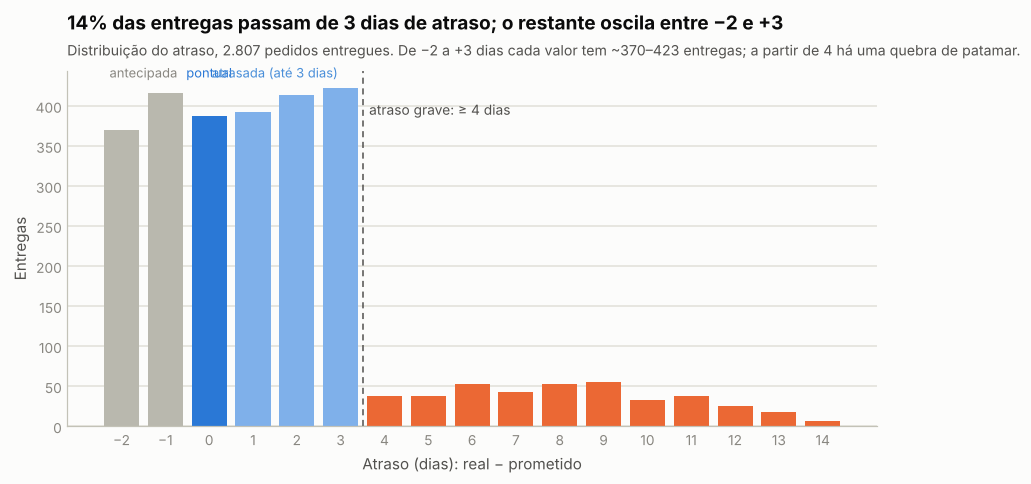

In [7]:
a = ent.atraso
K.update(n_ent=len(ent), pct_ant=float((a < 0).mean()), pct_pont=float((a == 0).mean()), pct_atr=float((a > 0).mean()),
         atraso_medio=float(a.mean()), atraso_mediano=float(a.median()), atraso_dp=float(a.std()), atraso_p90=float(a.quantile(.9)),
         atraso_max=int(a.max()), pct_grave=float((a >= LIM_GRAVE).mean()), n_grave=int((a >= LIM_GRAVE).sum()),
         dias_atraso_total=int(a.clip(lower=0).sum()))
atrasadas = a[a > 0]
K.update(sev_geral=float(atrasadas.mean()), sev_mediana=float(atrasadas.median()))
cont = a.value_counts().sort_index()
K['n_dias_ate3_cada'] = (int(cont.loc[-2:3].min()), int(cont.loc[-2:3].max()))   # quase uniforme entre -2 e +3

resumo = pd.DataFrame({'indicador': ['Entregas analisadas', 'Antecipadas', 'Pontuais', 'Atrasadas', 'Atraso médio (dias)', 'Atraso mediano (dias)',
                                     'Desvio padrão (dias)', 'P90 do atraso (dias)', 'Atraso máximo (dias)', 'Atraso médio só das atrasadas (dias)',
                                     'Entregas com atraso grave (≥ 4 dias)'],
                       'valor': [num(K['n_ent']), pct(K['pct_ant']), pct(K['pct_pont']), pct(K['pct_atr']), num(K['atraso_medio'], 2),
                                 num(K['atraso_mediano'], 1), num(K['atraso_dp'], 2), num(K['atraso_p90'], 1), K['atraso_max'],
                                 num(K['sev_geral'], 2), f"{num(K['n_grave'])} ({pct(K['pct_grave'])})"]})
display(resumo.style.hide(axis='index'))

fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = np.arange(a.min(), a.max() + 1); h = cont.reindex(x, fill_value=0)
cores = [GRAY if v < 0 else (BLUE if v == 0 else (ORANGE if v >= LIM_GRAVE else '#7fb0ea')) for v in x]
ax.bar(x, h.values, color=cores, width=.8)
ax.axvline(LIM_GRAVE - .5, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(LIM_GRAVE - .35, h.max() * .92, 'atraso grave: ≥ 4 dias', fontsize=9, color=INK2)
for lab, xx, c in [('antecipada', -1.5, MUTED), ('pontual', 0, BLUE), ('atrasada (até 3 dias)', 1.5, '#4a8fd9')]:
    ax.text(xx, h.max() * 1.03, lab, ha='center', fontsize=8.5, color=c)
estilo(ax); ax.set_xticks(x); ax.set_xlabel('Atraso (dias): real − prometido'); ax.set_ylabel('Entregas')
titulo(ax, f"{pct(K['pct_grave'],0)} das entregas passam de 3 dias de atraso; o restante oscila entre −2 e +3",
       f"Distribuição do atraso, {num(K['n_ent'])} pedidos entregues. De −2 a +3 dias cada valor tem ~{K['n_dias_ate3_cada'][0]}–{K['n_dias_ate3_cada'][1]} entregas; a partir de 4 há uma quebra de patamar.")
salvar(fig, 'a1_distribuicao_atraso'); plt.show()

In [8]:
display(Markdown(f"""
**Em uma frase:** a maioria dos atrasos é curta, mas existe uma cauda de atrasos graves.

- **{pct(K['pct_atr'],0)}** das entregas chegam depois do prometido, mas o atraso típico é **pequeno**: metade das entregas atrasa até {num(K['atraso_mediano'],0)} dia.
- Entre 2 dias antes e 3 dias depois, as entregas se distribuem de forma bem parecida ({K['n_dias_ate3_cada'][0]} a {K['n_dias_ate3_cada'][1]} entregas por dia de diferença). É o "vai e vem normal" do dia a dia.
- A partir de 4 dias a quantidade cai de patamar e aparece uma **cauda**: **{num(K['n_grave'])} entregas ({pct(K['pct_grave'])})** passam de 3 dias e chegam a **{K['atraso_max']} dias**. Por isso chamamos de **atraso grave** tudo que é 4 dias ou mais.

**Pergunta para o próximo capítulo:** quem está por trás dessa cauda?
"""))


**Em uma frase:** a maioria dos atrasos é curta, mas existe uma cauda de atrasos graves.

- **58%** das entregas chegam depois do prometido, mas o atraso típico é **pequeno**: metade das entregas atrasa até 1 dia.
- Entre 2 dias antes e 3 dias depois, as entregas se distribuem de forma bem parecida (370 a 423 entregas por dia de diferença). É o "vai e vem normal" do dia a dia.
- A partir de 4 dias a quantidade cai de patamar e aparece uma **cauda**: **403 entregas (14,4%)** passam de 3 dias e chegam a **14 dias**. Por isso chamamos de **atraso grave** tudo que é 4 dias ou mais.

**Pergunta para o próximo capítulo:** quem está por trás dessa cauda?


## Capítulo 2 · Quem atrasa?

Olhamos cada fornecedor por dois ângulos: **frequência** (quantas entregas atrasam) e **gravidade** (quantos dias atrasa quando atrasa). Também medimos a **previsibilidade**: um fornecedor previsível atrasa sempre de forma parecida; um imprevisível varia muito de uma entrega para outra.

In [9]:
f = metricas_fornecedor(ped)
f['cronico'] = f.severidade.pipe(z_modificado) > 3.5
cron = f[f.cronico].sort_values('atraso_medio', ascending=False)
nao = f[~f.cronico]
K['cron_nomes'] = list(cron.fornecedor); K['n_forn'] = len(f)
K.update(cron_sev=[float(v) for v in cron.severidade], cron_pct=[float(v) for v in cron.pct_atrasado], cron_rel=[float(v) for v in cron.atraso_rel],
         cron_prazo=[float(v) for v in cron.prazo_prometido], cron_tier=list(cron.tier), cron_pais=list(cron.pais),
         cron_share_dias=float(cron.share_dias_atraso.sum()), cron_share_gasto=float(cron.share_gasto.sum()),
         cron_share_pedidos=float(cron.pedidos.sum() / f.pedidos.sum()),
         nao_pct_min=float(nao.pct_atrasado.min()), nao_pct_max=float(nao.pct_atrasado.max()),
         nao_sev_min=float(nao.severidade.min()), nao_sev_max=float(nao.severidade.max()),
         nao_atraso_min=float(nao.atraso_medio.min()), nao_atraso_max=float(nao.atraso_medio.max()),
         nao_dp_med=float(nao.desvio.mean()), cron_dp_med=float(cron.desvio.mean()),
         grave_share_cron=float(ent[ent.grave == 1].fornecedor.isin(K['cron_nomes']).mean()))

cols = ['fornecedor', 'tier', 'pais', 'pedidos', 'pct_antecipado', 'pct_pontual', 'pct_atrasado', 'atraso_medio', 'atraso_mediano', 'severidade',
        'desvio', 'p90', 'maximo', 'pct_grave', 'atraso_rel', 'share_dias_atraso']
rk = f.sort_values('atraso_medio', ascending=False)[cols]
display(rk.style.hide(axis='index').format({'pct_antecipado': '{:.0%}', 'pct_pontual': '{:.0%}', 'pct_atrasado': '{:.0%}', 'atraso_medio': '{:.2f}',
        'atraso_mediano': '{:.1f}', 'severidade': '{:.2f}', 'desvio': '{:.2f}', 'p90': '{:.1f}', 'pct_grave': '{:.0%}', 'atraso_rel': '{:.0%}',
        'share_dias_atraso': '{:.1%}'}).background_gradient(subset=['atraso_medio'], cmap='Oranges'))

fornecedor,tier,pais,pedidos,pct_antecipado,pct_pontual,pct_atrasado,atraso_medio,atraso_mediano,severidade,desvio,p90,maximo,pct_grave,atraso_rel,share_dias_atraso
SUP-04,B,USA,145,0%,0%,100%,7.77,8.0,7.77,3.08,12.0,14.000000,92%,43%,19.5%
SUP-17,A,Turkey,142,0%,0%,100%,7.58,8.0,7.58,3.22,12.0,14.000000,87%,108%,18.7%
SUP-11,C,India,158,0%,0%,100%,7.46,7.0,7.46,2.88,11.0,14.000000,92%,21%,20.4%
SUP-16,C,Germany,141,30%,13%,57%,0.77,1.0,2.06,1.70,3.0,3.000000,0%,2%,2.9%
SUP-03,C,India,150,27%,20%,53%,0.67,1.0,2.04,1.64,3.0,3.000000,0%,2%,2.8%
SUP-07,A,Turkey,137,29%,18%,53%,0.66,1.0,2.04,1.68,3.0,3.000000,0%,9%,2.6%
SUP-15,B,France,130,28%,16%,55%,0.65,1.0,2.04,1.78,3.0,3.000000,0%,4%,2.5%
SUP-01,B,Turkey,148,32%,16%,53%,0.63,1.0,2.08,1.74,3.0,3.000000,0%,3%,2.8%
SUP-08,B,Germany,136,36%,9%,55%,0.60,1.0,2.08,1.84,3.0,3.000000,0%,3%,2.7%
SUP-18,B,Poland,137,34%,16%,50%,0.55,0.0,2.10,1.73,3.0,3.000000,0%,3%,2.5%


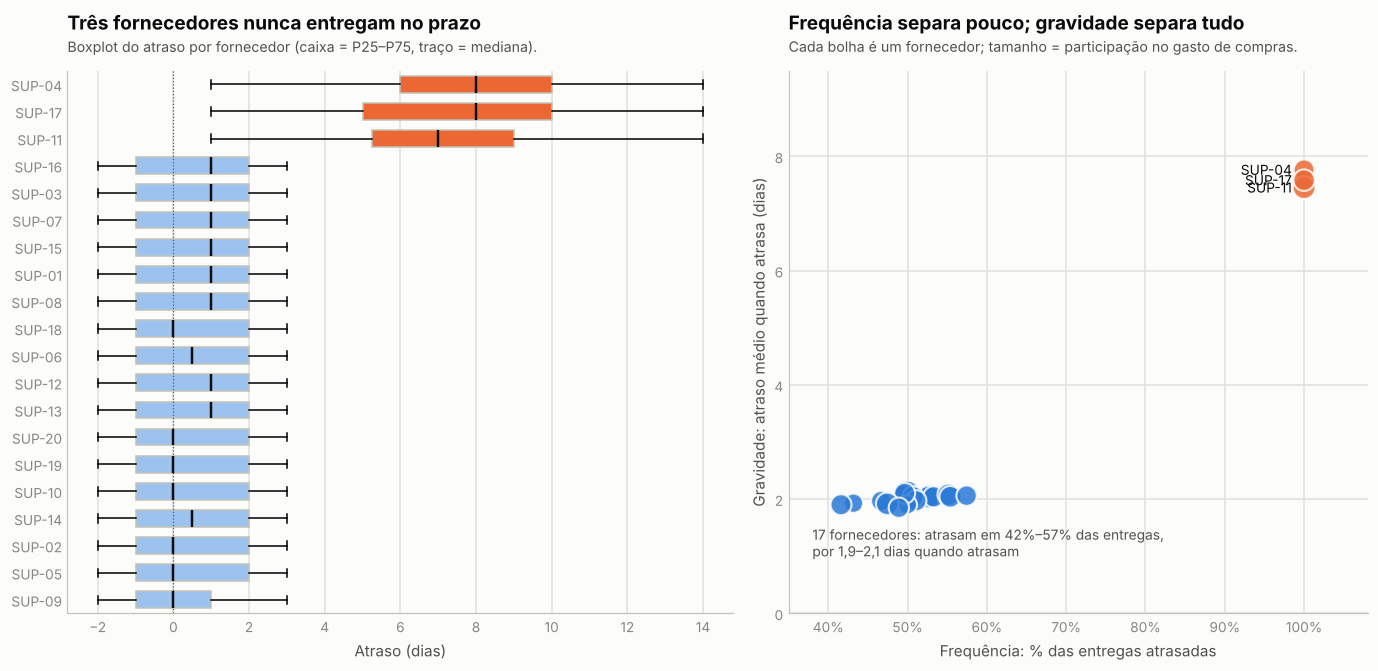

In [10]:
ordem = f.sort_values('atraso_medio', ascending=True).fornecedor.tolist()
dados = [ent.loc[ent.fornecedor == s, 'atraso'].values for s in ordem]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={'width_ratios': [1.15, 1]})
bp = ax1.boxplot(dados, vert=False, patch_artist=True, widths=.62, whis=1.5, flierprops=dict(marker='o', ms=3, mfc=MUTED, mec='none', alpha=.6),
                 medianprops=dict(color=INK, lw=1.6))
for patch, s in zip(bp['boxes'], ordem):
    patch.set_facecolor(ORANGE if s in K['cron_nomes'] else '#9cc3f0'); patch.set_edgecolor(AXIS)
ax1.set_yticks(range(1, len(ordem) + 1)); ax1.set_yticklabels(ordem); ax1.axvline(0, color=INK2, lw=.8, ls=':')
estilo(ax1, 'x'); ax1.set_xlabel('Atraso (dias)')
titulo(ax1, 'Três fornecedores nunca entregam no prazo', 'Boxplot do atraso por fornecedor (caixa = P25–P75, traço = mediana).')
sz = f.share_gasto * 3800
ax2.scatter(f.pct_atrasado * 100, f.severidade, s=sz, c=[CRON_COR(v) for v in f.cronico], alpha=.85, edgecolor=SURFACE, lw=1.4)
for r in f[f.cronico].itertuples(): ax2.annotate(r.fornecedor, (r.pct_atrasado * 100, r.severidade), xytext=(-8, 0), textcoords='offset points', ha='right', va='center', fontsize=9)
ax2.set_xlim(35, 108); ax2.set_ylim(0, 9.5); estilo(ax2, 'both')
ax2.set_xlabel('Frequência: % das entregas atrasadas'); ax2.set_ylabel('Gravidade: atraso médio quando atrasa (dias)')
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.text(38, 1.0, f"17 fornecedores: atrasam em {pct(K['nao_pct_min'],0)}–{pct(K['nao_pct_max'],0)} das entregas,\npor {num(K['nao_sev_min'],1)}–{num(K['nao_sev_max'],1)} dias quando atrasam", fontsize=9, color=INK2)
titulo(ax2, 'Frequência separa pouco; gravidade separa tudo', 'Cada bolha é um fornecedor; tamanho = participação no gasto de compras.')
plt.tight_layout(); salvar(fig, 'a2_fornecedores_frequencia_gravidade'); plt.show()

In [11]:
display(Markdown(f"""
**Em uma frase:** três fornecedores atrasam em todas as entregas e por muito mais tempo que os outros 17.

- ✅ **Fato:** **{', '.join(K['cron_nomes'])}** atrasam **{pct(K['cron_pct'][0],0)} das entregas**, por **{num(min(K['cron_sev']),1)} a {num(max(K['cron_sev']),1)} dias** em média. Juntos respondem por **{pct(K['cron_share_dias'],0)} de todos os dias de atraso**, com **{pct(K['cron_share_gasto'],0)} do gasto**: o atraso é muito maior do que a importância deles nas compras.
- ✅ **Fato:** os outros **{K['n_forn']-3} fornecedores** são muito parecidos entre si: atrasam entre **{pct(K['nao_pct_min'],0)} e {pct(K['nao_pct_max'],0)}** das entregas, por **{num(K['nao_sev_min'],1)}–{num(K['nao_sev_max'],1)} dias**. **Nenhum** tem atraso grave (o máximo é 3 dias).
- ✅ **Fato:** **{pct(K['grave_share_cron'],0)}** dos atrasos graves (4 dias ou mais) vêm desses três.
- **Frequência × gravidade:** aqui não existe o fornecedor "atrasa pouco, mas sempre" nem o "raramente, mas por muito tempo". Os três problemáticos têm os dois problemas ao mesmo tempo, e por isso aparecem isolados no canto do gráfico.
- **Previsibilidade:** os três também são os mais imprevisíveis (variação típica de {num(K['cron_dp_med'],1)} dias, contra {num(K['nao_dp_med'],1)} dos demais).
- **Peso no contrato:** o atraso estica o prazo combinado em {pct(K['cron_rel'][0],0)} ({K['cron_nomes'][0]}), {pct(K['cron_rel'][1],0)} ({K['cron_nomes'][1]}) e {pct(K['cron_rel'][2],0)} ({K['cron_nomes'][2]}). O mesmo atraso em dias pesa muito mais em prazos curtos.
"""))


**Em uma frase:** três fornecedores atrasam em todas as entregas e por muito mais tempo que os outros 17.

- ✅ **Fato:** **SUP-04, SUP-17, SUP-11** atrasam **100% das entregas**, por **7,5 a 7,8 dias** em média. Juntos respondem por **59% de todos os dias de atraso**, com **16% do gasto**: o atraso é muito maior do que a importância deles nas compras.
- ✅ **Fato:** os outros **17 fornecedores** são muito parecidos entre si: atrasam entre **42% e 57%** das entregas, por **1,9–2,1 dias**. **Nenhum** tem atraso grave (o máximo é 3 dias).
- ✅ **Fato:** **100%** dos atrasos graves (4 dias ou mais) vêm desses três.
- **Frequência × gravidade:** aqui não existe o fornecedor "atrasa pouco, mas sempre" nem o "raramente, mas por muito tempo". Os três problemáticos têm os dois problemas ao mesmo tempo, e por isso aparecem isolados no canto do gráfico.
- **Previsibilidade:** os três também são os mais imprevisíveis (variação típica de 3,1 dias, contra 1,7 dos demais).
- **Peso no contrato:** o atraso estica o prazo combinado em 43% (SUP-04), 108% (SUP-17) e 21% (SUP-11). O mesmo atraso em dias pesa muito mais em prazos curtos.


## Capítulo 3 · Existe algum padrão?

Se o atraso dependesse do **país**, do **tipo (tier)** do fornecedor ou de ele ser **fonte única**, a empresa poderia agir por categoria. Vamos testar. Mas há uma armadilha: os 3 fornecedores problemáticos estão em certos países e tiers, e podem **dar a impressão** de que o país ou o tier é o culpado. Por isso cada comparação é feita **com e sem** eles.

dimensão,p-valor (todos),efeito ε² (todos),p-valor (sem os 3 crônicos),efeito ε² (sem os 3)
País do fornecedor,5.4e-56,0.097,0.924,0.0008
Tier,1.5e-19,0.031,0.098,0.0020
Fonte única,2.3e-16,0.024,0.859,0.0000


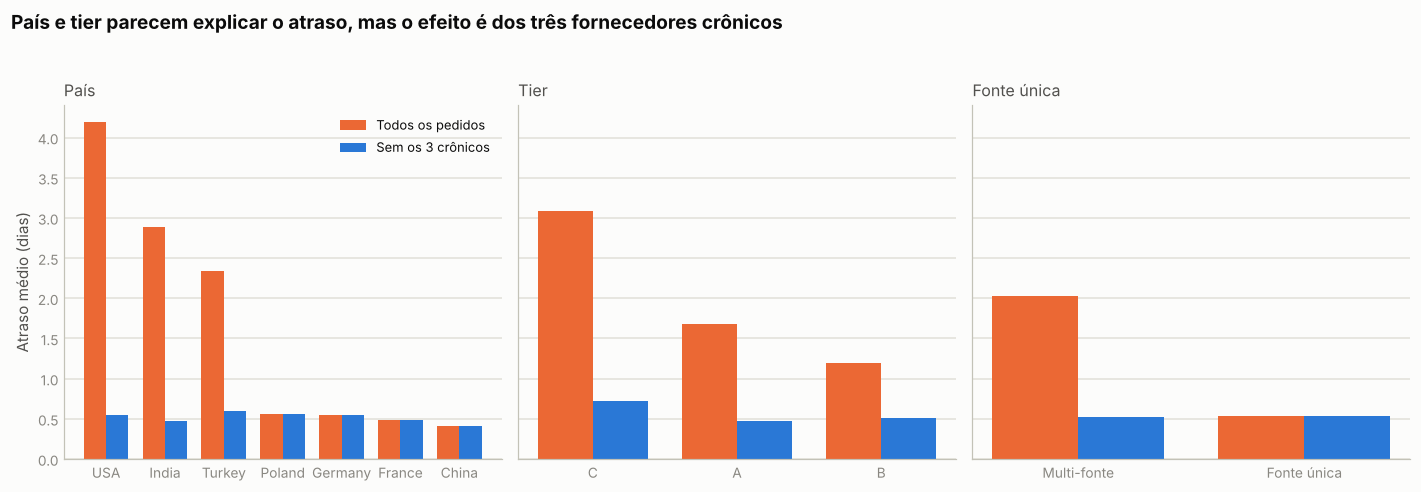

In [12]:
ent['cronico'] = ent.fornecedor.isin(K['cron_nomes'])
ent['log_valor'] = np.log1p(ent.valor); ent['log_itens'] = np.log1p(ent.itens)
ent['single'] = ent.is_single_source.map({1: 'Fonte única', 0: 'Multi-fonte'})
ent_nc = ent[~ent.cronico]

def kw_p(df, col): return float(stats.kruskal(*[g.atraso.values for _, g in df.groupby(col)]).pvalue)
def eps2(df, col):  # tamanho de efeito (epsilon²) do Kruskal–Wallis
    H = stats.kruskal(*[g.atraso.values for _, g in df.groupby(col)]).statistic; return float(H / (len(df) - 1))

padroes = {}
for col, nome in [('pais', 'País do fornecedor'), ('tier', 'Tier'), ('single', 'Fonte única')]:
    padroes[col] = dict(nome=nome, p_todos=kw_p(ent, col), p_sem=kw_p(ent_nc, col), e_todos=eps2(ent, col), e_sem=eps2(ent_nc, col))
K['padroes'] = padroes
tab = pd.DataFrame(padroes).T[['nome', 'p_todos', 'e_todos', 'p_sem', 'e_sem']]
tab.columns = ['dimensão', 'p-valor (todos)', 'efeito ε² (todos)', 'p-valor (sem os 3 crônicos)', 'efeito ε² (sem os 3)']
display(tab.style.hide(axis='index').format({'p-valor (todos)': '{:.2g}', 'efeito ε² (todos)': '{:.3f}', 'p-valor (sem os 3 crônicos)': '{:.3f}', 'efeito ε² (sem os 3)': '{:.4f}'}))

fig, axs = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
for ax, (col, nome) in zip(axs, [('pais', 'País'), ('tier', 'Tier'), ('single', 'Fonte única')]):
    m1 = ent.groupby(col).atraso.mean(); m2 = ent_nc.groupby(col).atraso.mean().reindex(m1.index)
    idx = m1.sort_values(ascending=False).index; xx = np.arange(len(idx)); w = .38
    ax.bar(xx - w / 2, m1.loc[idx], w, color=ORANGE, label='Todos os pedidos')
    ax.bar(xx + w / 2, m2.loc[idx], w, color=BLUE, label='Sem os 3 crônicos')
    ax.set_xticks(xx); ax.set_xticklabels(idx, rotation=0, fontsize=8.5); estilo(ax); ax.set_title(nome, loc='left', fontsize=10.5, color=INK2)
axs[0].set_ylabel('Atraso médio (dias)'); axs[0].legend(fontsize=8.5, loc='upper right')
fig.suptitle('País e tier parecem explicar o atraso, mas o efeito é dos três fornecedores crônicos', x=.01, ha='left', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout(); salvar(fig, 'a3_padroes_confundimento'); plt.show()

In [13]:
p = K['padroes']
sig = lambda v: 'deixa de ser significativa' if v > .05 else 'continua significativa'   # noqa: E731
display(Markdown(f"""
**Em uma frase:** país e tier parecem importar, mas é só porque os 3 fornecedores problemáticos estão dentro deles.

- 🔗 **Associação:** olhando todos os pedidos, alguns países e tiers parecem atrasar mais. Por exemplo, **{ent.groupby('pais').atraso.mean().idxmax()}** tem o maior atraso médio ({num(ent.groupby('pais').atraso.mean().max(),1)} dias), e os fornecedores de **fonte única** parecem *mais pontuais* ({num(ent[ent.is_single_source==1].atraso.mean(),1)} vs {num(ent[ent.is_single_source==0].atraso.mean(),1)} dia).
- ✅ **Fato:** ao tirar os 3 fornecedores, a diferença por país, por tier e por fonte única **{'desaparece' if max(p['pais']['p_sem'], p['tier']['p_sem'], p['single']['p_sem']) > .05 else 'continua em parte'}**. O efeito aparente vinha de **fornecedores específicos** (e nenhum deles é de fonte única).
- **Consequência prática:** agir por *categoria* de fornecedor (país ou tier) seria um erro; agir por *fornecedor* faz sentido.

<details><summary>🔧 Nota técnica</summary>

Teste de Kruskal–Wallis (compara grupos sem supor distribuição normal) e tamanho de efeito ε². **Todos os pedidos:** país ε² = {num(p['pais']['e_todos'],3)}, tier ε² = {num(p['tier']['e_todos'],3)}, fonte única ε² = {num(p['single']['e_todos'],3)}. **Sem os 3 crônicos:** país p = {num(p['pais']['p_sem'],2)} ({sig(p['pais']['p_sem'])}), tier p = {num(p['tier']['p_sem'],2)} ({sig(p['tier']['p_sem'])}), fonte única p = {num(p['single']['p_sem'],2)} ({sig(p['single']['p_sem'])}).
</details>
"""))
cat = (T['purchase_order_line'].merge(ent[['po_id', 'atraso']], on='po_id').merge(T['product'][['product_id', 'category']], on='product_id')
       .groupby('category').atraso.agg(['mean', 'median', lambda s: (s > 0).mean(), 'count']).round(2))
cat.columns = ['atraso médio', 'mediana', '% atrasado', 'linhas de pedido']; K['cat_min'] = float(cat['atraso médio'].min()); K['cat_max'] = float(cat['atraso médio'].max())
display(Markdown(f"**Por tipo de produto:** o atraso médio varia só de **{num(K['cat_min'],2)}** a **{num(K['cat_max'],2)}** dia. Todos os produtos são comprados dos mesmos 20 fornecedores, então **não há diferença por produto**."))
display(cat)


**Em uma frase:** país e tier parecem importar, mas é só porque os 3 fornecedores problemáticos estão dentro deles.

- 🔗 **Associação:** olhando todos os pedidos, alguns países e tiers parecem atrasar mais. Por exemplo, **USA** tem o maior atraso médio (4,2 dias), e os fornecedores de **fonte única** parecem *mais pontuais* (0,5 vs 2,0 dia).
- ✅ **Fato:** ao tirar os 3 fornecedores, a diferença por país, por tier e por fonte única **desaparece**. O efeito aparente vinha de **fornecedores específicos** (e nenhum deles é de fonte única).
- **Consequência prática:** agir por *categoria* de fornecedor (país ou tier) seria um erro; agir por *fornecedor* faz sentido.

<details><summary>🔧 Nota técnica</summary>

Teste de Kruskal–Wallis (compara grupos sem supor distribuição normal) e tamanho de efeito ε². **Todos os pedidos:** país ε² = 0,097, tier ε² = 0,031, fonte única ε² = 0,024. **Sem os 3 crônicos:** país p = 0,92 (deixa de ser significativa), tier p = 0,10 (deixa de ser significativa), fonte única p = 0,86 (deixa de ser significativa).
</details>


**Por tipo de produto:** o atraso médio varia só de **1,58** a **1,74** dia. Todos os produtos são comprados dos mesmos 20 fornecedores, então **não há diferença por produto**.

,atraso médio,mediana,% atrasado,linhas de pedido
category,,,,
Bearings,1.70,1.0,0.59,1413
Casings,1.58,1.0,0.57,1464
Electronics,1.69,1.0,0.60,1453
Fasteners,1.74,1.0,0.59,1296
Hydraulics,1.73,1.0,0.60,1356


### O problema muda ao longo do tempo?

Temos **24 meses** de pedidos. Dá para ver se o atraso está **piorando, melhorando** ou **variando com a época do ano**. Não usamos modelos de previsão de séries temporais (ARIMA, Prophet): 24 meses são poucos para separar sazonalidade de ruído, e um modelo complexo passaria uma falsa sensação de precisão.

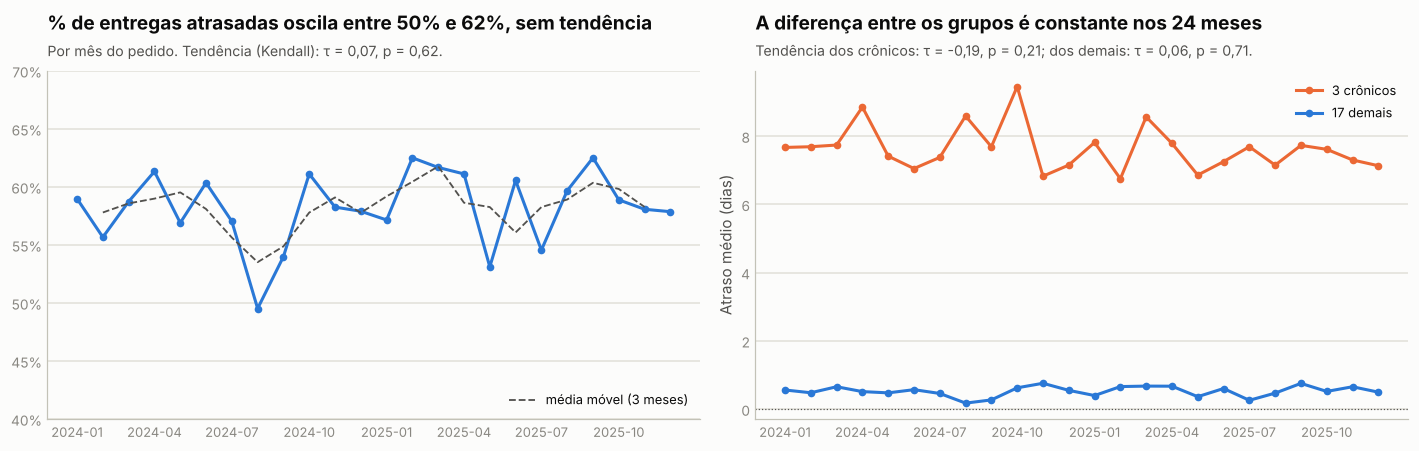


**Em uma frase:** o problema é estável: não está piorando nem melhorando, e não depende da época do ano.

- ✅ **Fato:** a porcentagem de entregas atrasadas oscila entre **50%** e **62%** ao longo dos meses, **sem tendência** de alta ou de queda. 2024 e 2025 têm atraso médio parecido (**1,68** vs **1,61** dia).
- ✅ **Fato:** não há meses "bons" ou "ruins" para os fornecedores: o atraso não segue o calendário.
- **O que isso significa:** o problema é **estrutural**. Não vai sumir sozinho e também não é um pico passageiro; pede ação sobre os fornecedores, não uma "campanha de fim de ano".
- A forte sazonalidade da **demanda** (agosto e fim de ano, no notebook principal) **não** aparece nos atrasos dos fornecedores.

<details><summary>🔧 Nota técnica</summary>

Tendência da % de atrasadas: τ de Kendall = 0,07, p = 0,62. Mês do ano: Kruskal–Wallis, p = 0,68. 2024 vs 2025: Mann–Whitney, p = 0,95. Atraso médio mensal dos 3 crônicos: τ = -0,19, p = 0,21; dos demais: τ = 0,06, p = 0,71.
</details>


In [14]:
mes = ent.groupby(['ano_mes', 'cronico']).agg(media=('atraso', 'mean'), pct_atr=('atrasado', 'mean'), n=('po_id', 'count')).reset_index()
tot = ent.groupby('ano_mes').agg(pct_atr=('atrasado', 'mean'), media=('atraso', 'mean')).reset_index()
meses = tot.ano_mes.tolist(); xm = np.arange(len(meses))
def tau(s): r = stats.kendalltau(np.arange(len(s)), s); return float(r.statistic), float(r.pvalue)
t_tot = tau(tot.pct_atr); t_med = tau(tot.media)
t_cro = tau(mes[mes.cronico].media); t_nao = tau(mes[~mes.cronico].media)
p_sazon = float(stats.kruskal(*[g.atraso.values for _, g in ent.groupby('mes')]).pvalue)
p_sazon_cro = float(stats.kruskal(*[g.atraso.values for _, g in ent[ent.cronico].groupby('mes')]).pvalue)
p_ano = float(stats.mannwhitneyu(ent[ent.ano == 2024].atraso, ent[ent.ano == 2025].atraso).pvalue)
K.update(tau_tot=t_tot, tau_cro=t_cro, tau_nao=t_nao, p_sazon=p_sazon, p_sazon_cro=p_sazon_cro, p_ano=p_ano,
         pct_atr_mes_min=float(tot.pct_atr.min()), pct_atr_mes_max=float(tot.pct_atr.max()),
         media_24=float(ent[ent.ano == 2024].atraso.mean()), media_25=float(ent[ent.ano == 2025].atraso.mean()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.plot(xm, tot.pct_atr * 100, color=BLUE, lw=2, marker='o', ms=4); ax1.plot(xm, tot.pct_atr.rolling(3, center=True).mean() * 100, color=INK2, lw=1.2, ls='--', label='média móvel (3 meses)')
ax1.set_ylim(40, 70); ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); estilo(ax1)
ax1.set_xticks(xm[::3]); ax1.set_xticklabels([meses[i] for i in xm[::3]], fontsize=8.5); ax1.legend(fontsize=8.5, loc='lower right')
titulo(ax1, f"% de entregas atrasadas oscila entre {pct(K['pct_atr_mes_min'],0)} e {pct(K['pct_atr_mes_max'],0)}, sem tendência", f"Por mês do pedido. Tendência (Kendall): τ = {num(t_tot[0],2)}, p = {num(t_tot[1],2)}.")
for flag, cor, rot in [(True, ORANGE, '3 crônicos'), (False, BLUE, '17 demais')]:
    s = mes[mes.cronico == flag]; ax2.plot(np.arange(len(s)), s.media, color=cor, lw=2, marker='o', ms=4, label=rot)
ax2.axhline(0, color=INK2, lw=.8, ls=':'); estilo(ax2); ax2.set_ylabel('Atraso médio (dias)'); ax2.legend(fontsize=8.5)
ax2.set_xticks(xm[::3]); ax2.set_xticklabels([meses[i] for i in xm[::3]], fontsize=8.5)
titulo(ax2, 'A diferença entre os grupos é constante nos 24 meses', f"Tendência dos crônicos: τ = {num(t_cro[0],2)}, p = {num(t_cro[1],2)}; dos demais: τ = {num(t_nao[0],2)}, p = {num(t_nao[1],2)}.")
plt.tight_layout(); salvar(fig, 'a4_evolucao_atrasos'); plt.show()
display(Markdown(f"""
**Em uma frase:** o problema é estável: não está piorando nem melhorando, e não depende da época do ano.

- ✅ **Fato:** a porcentagem de entregas atrasadas oscila entre **{pct(K['pct_atr_mes_min'],0)}** e **{pct(K['pct_atr_mes_max'],0)}** ao longo dos meses, **sem tendência** de alta ou de queda. 2024 e 2025 têm atraso médio parecido (**{num(K['media_24'],2)}** vs **{num(K['media_25'],2)}** dia).
- ✅ **Fato:** não há meses "bons" ou "ruins" para os fornecedores: o atraso não segue o calendário.
- **O que isso significa:** o problema é **estrutural**. Não vai sumir sozinho e também não é um pico passageiro; pede ação sobre os fornecedores, não uma "campanha de fim de ano".
- A forte sazonalidade da **demanda** (agosto e fim de ano, no notebook principal) **não** aparece nos atrasos dos fornecedores.

<details><summary>🔧 Nota técnica</summary>

Tendência da % de atrasadas: τ de Kendall = {num(t_tot[0],2)}, p = {num(t_tot[1],2)}. Mês do ano: Kruskal–Wallis, p = {num(p_sazon,2)}. 2024 vs 2025: Mann–Whitney, p = {num(p_ano,2)}. Atraso médio mensal dos 3 crônicos: τ = {num(t_cro[0],2)}, p = {num(t_cro[1],2)}; dos demais: τ = {num(t_nao[0],2)}, p = {num(t_nao[1],2)}.
</details>
"""))

## Capítulo 4 · O que está por trás dos atrasos?

Duas famílias de explicações possíveis:
1. **Características do pedido:** valor, quantidade de itens, urgência, mês, dia da semana, prazo prometido.
2. **Quem é o fornecedor.**

Se o atraso depender do pedido, a empresa pode agir pedido a pedido; se depender do fornecedor, deve agir sobre o fornecedor. Vamos medir quanto cada família explica.

<details><summary>🔧 Nota técnica: por que Spearman e não Pearson</summary>

O atraso é um número inteiro, limitado (−2 a 14) e assimétrico. O coeficiente de Spearman trabalha com a *ordem* dos valores e é robusto a isso; o de Pearson aparece só como conferência.
</details>

In [15]:
def corr_tab(df, rotulo):
    linhas = []
    for c in ['log_valor', 'log_itens', 'linhas', 'expedited', 'prazo_prometido', 'mes', 'dow']:
        r_s = stats.spearmanr(df.atraso, df[c]); r_p = stats.pearsonr(df.atraso, df[c])
        linhas.append({'amostra': rotulo, 'variável': c, 'Spearman ρ': r_s.statistic, 'p (Spearman)': r_s.pvalue, 'Pearson r': r_p.statistic, 'p (Pearson)': r_p.pvalue})
    return pd.DataFrame(linhas)
ct = pd.concat([corr_tab(ent, 'Todos'), corr_tab(ent_nc, '17 sem crônicos'), corr_tab(ent[ent.cronico], '3 crônicos')], ignore_index=True)
K['corr_maxabs_nc'] = float(ct[ct.amostra == '17 sem crônicos']['Spearman ρ'].abs().max())
K['corr_sig_nc'] = ct[(ct.amostra == '17 sem crônicos') & (ct['p (Spearman)'] < .05)]['variável'].tolist()
display(ct.style.hide(axis='index').format({'Spearman ρ': '{:+.3f}', 'p (Spearman)': '{:.3f}', 'Pearson r': '{:+.3f}', 'p (Pearson)': '{:.3f}'})
        .background_gradient(subset=['Spearman ρ'], cmap='RdBu_r', vmin=-.3, vmax=.3))

amostra,variável,Spearman ρ,p (Spearman),Pearson r,p (Pearson)
Todos,log_valor,+0.013,0.478,-0.005,0.787
Todos,log_itens,+0.028,0.142,+0.012,0.517
Todos,linhas,+0.039,0.039,+0.030,0.115
Todos,expedited,-0.031,0.105,-0.029,0.119
Todos,prazo_prometido,+0.085,0.000,+0.129,0.000
Todos,mes,-0.005,0.793,-0.009,0.646
Todos,dow,+0.000,0.982,-0.005,0.803
17 sem crônicos,log_valor,+0.021,0.306,+0.011,0.585
17 sem crônicos,log_itens,+0.034,0.102,+0.022,0.277
17 sem crônicos,linhas,+0.031,0.129,+0.031,0.126


### Quanto cada fator explica?

Usamos duas ferramentas simples: uma estima **a chance de atrasar** (regressão logística) e outra estima **quantos dias a mais ou a menos** (regressão linear). Elas são ajustadas só nos **17 fornecedores normais**, para ver se algo no pedido explica o atraso. Os 3 problemáticos ficam de fora por um motivo técnico: atrasam 100% das vezes, o que impede o cálculo da regressão logística. Para eles, a pergunta é outra (a identidade do fornecedor), respondida em seguida.

*Como ler as tabelas:* na logística, *odds ratio* = 1 significa "nenhum efeito"; na linear, o efeito é medido em dias.

In [16]:
form = 'expedited + log_valor + log_itens + linhas + prazo_prometido + mes + dow'
lg = smf.logit('atrasado ~ ' + form, data=ent_nc).fit(disp=0)
ci = lg.conf_int(); orr = pd.DataFrame({'odds ratio': np.exp(lg.params), 'IC95% inf': np.exp(ci[0]), 'IC95% sup': np.exp(ci[1]), 'p-valor': lg.pvalues}).drop('Intercept')
ols = smf.ols('atraso ~ ' + form, data=ent_nc).fit(cov_type='HC3')
coef = pd.DataFrame({'efeito (dias)': ols.params, 'p-valor': ols.pvalues}).drop('Intercept')
K.update(logit_llr_p=float(lg.llr_pvalue), logit_pseudo_r2=float(lg.prsquared), ols_r2=float(ols.rsquared), ols_r2_adj=float(ols.rsquared_adj), ols_f_p=float(ols.f_pvalue),
         logit_sig=orr[orr['p-valor'] < .05].index.tolist(), ols_sig=coef[coef['p-valor'] < .05].index.tolist())
display(Markdown('**Regressão logística: atraso (sim/não) entre os 17 fornecedores normais**'))
display(orr.style.format({'odds ratio': '{:.3f}', 'IC95% inf': '{:.3f}', 'IC95% sup': '{:.3f}', 'p-valor': '{:.3f}'}))
display(Markdown('**Regressão linear: dias de atraso entre os 17 fornecedores normais**'))
display(coef.style.format({'efeito (dias)': '{:+.4f}', 'p-valor': '{:.3f}'}))

# --- Quanto da variação é explicada pelo FORNECEDOR vs pelo PEDIDO (todos os pedidos) ---
r2_forn = smf.ols('atraso ~ C(fornecedor)', data=ent).fit().rsquared
r2_cron = smf.ols('atraso ~ cronico', data=ent).fit().rsquared
r2_ped = smf.ols('atraso ~ ' + form, data=ent).fit().rsquared
K.update(r2_forn=float(r2_forn), r2_cron=float(r2_cron), r2_ped=float(r2_ped))
ct2 = pd.crosstab(ent.cronico.map({True: '3 crônicos', False: '17 demais'}), ent.grave.map({1.0: 'atraso grave (≥ 4)', 0.0: 'sem atraso grave'}))
display(ct2)
fis = stats.fisher_exact(pd.crosstab(ent.cronico, ent.grave)); K['fisher_p'] = float(fis.pvalue)

**Regressão logística: atraso (sim/não) entre os 17 fornecedores normais**

,odds ratio,IC95% inf,IC95% sup,p-valor
expedited,0.950,0.736,1.226,0.692
log_valor,0.953,0.865,1.050,0.332
log_itens,1.007,0.837,1.211,0.943
linhas,1.078,0.969,1.199,0.169
prazo_prometido,1.009,0.999,1.019,0.069
mes,0.998,0.975,1.022,0.878
dow,1.046,1.004,1.089,0.033


**Regressão linear: dias de atraso entre os 17 fornecedores normais**

,efeito (dias),p-valor
expedited,-0.1172,0.298
log_valor,-0.0203,0.622
log_itens,+0.0190,0.805
linhas,+0.0527,0.253
prazo_prometido,+0.0086,0.036
mes,+0.0008,0.937
dow,+0.0274,0.115


grave,atraso grave (≥ 4),sem atraso grave
cronico,,
17 demais,0,2362
3 crônicos,403,42


In [17]:
display(Markdown(f"""
**Em uma frase:** o que explica o atraso é quem entrega, e não o pedido.

- ✅ **Fato:** entre os fornecedores normais, **nada no pedido** (tamanho, valor, urgência, mês, dia da semana) ajuda a prever se ele atrasa: as ferramentas explicam menos de {pct(max(K['ols_r2'],.001),1)} da variação, ou seja, praticamente zero.
- ✅ **Fato:** a **identidade do fornecedor** explica **{pct(K['r2_forn'],0)}** da variação dos dias de atraso, contra {pct(K['r2_ped'],1)} das características do pedido. Só saber se o fornecedor é um dos três problemáticos já explica {pct(K['r2_cron'],0)}.
- ✅ **Fato:** o atraso grave (4 dias ou mais) só acontece nesses três (teste exato de Fisher, p < 0,001).
- **Consequência prática:** o atraso é uma característica do **fornecedor**, não do pedido. Ações pedido a pedido (priorizar, acompanhar caso a caso) não têm apoio nos dados; gestão de fornecedor tem.

<details><summary>🔧 Nota técnica</summary>

Spearman máximo entre atraso e atributos do pedido (17 normais): |ρ| = {num(K['corr_maxabs_nc'],3)}; fatores com p < 0,05: {', '.join(K['corr_sig_nc']) or 'nenhum'}. Regressão logística: p global = {num(K['logit_llr_p'],2)}, pseudo-R² = {num(K['logit_pseudo_r2'],4)}. Regressão linear (erros robustos HC3): R² = {num(K['ols_r2'],4)}, p = {num(K['ols_f_p'],2)}. Fatores isolados que apareçam como "significativos" devem ser lidos como ruído de múltiplos testes, dado o R² ≈ 0.
</details>
"""))


**Em uma frase:** o que explica o atraso é quem entrega, e não o pedido.

- ✅ **Fato:** entre os fornecedores normais, **nada no pedido** (tamanho, valor, urgência, mês, dia da semana) ajuda a prever se ele atrasa: as ferramentas explicam menos de 0,4% da variação, ou seja, praticamente zero.
- ✅ **Fato:** a **identidade do fornecedor** explica **63%** da variação dos dias de atraso, contra 1,9% das características do pedido. Só saber se o fornecedor é um dos três problemáticos já explica 63%.
- ✅ **Fato:** o atraso grave (4 dias ou mais) só acontece nesses três (teste exato de Fisher, p < 0,001).
- **Consequência prática:** o atraso é uma característica do **fornecedor**, não do pedido. Ações pedido a pedido (priorizar, acompanhar caso a caso) não têm apoio nos dados; gestão de fornecedor tem.

<details><summary>🔧 Nota técnica</summary>

Spearman máximo entre atraso e atributos do pedido (17 normais): |ρ| = 0,036; fatores com p < 0,05: nenhum. Regressão logística: p global = 0,16, pseudo-R² = 0,0032. Regressão linear (erros robustos HC3): R² = 0,0042, p = 0,16. Fatores isolados que apareçam como "significativos" devem ser lidos como ruído de múltiplos testes, dado o R² ≈ 0.
</details>


## Capítulo 5 · Isso custa caro para o negócio?

**Regra do capítulo:** só atribuímos impacto onde os dados permitem **medir**. Para cada tipo de impacto perguntamos: *há evidência de efeito?* Quando não dá para medir, dizemos isso claramente e a ideia vira **hipótese**, nunca um número inventado.

### 5.1 Preço, volume e urgência

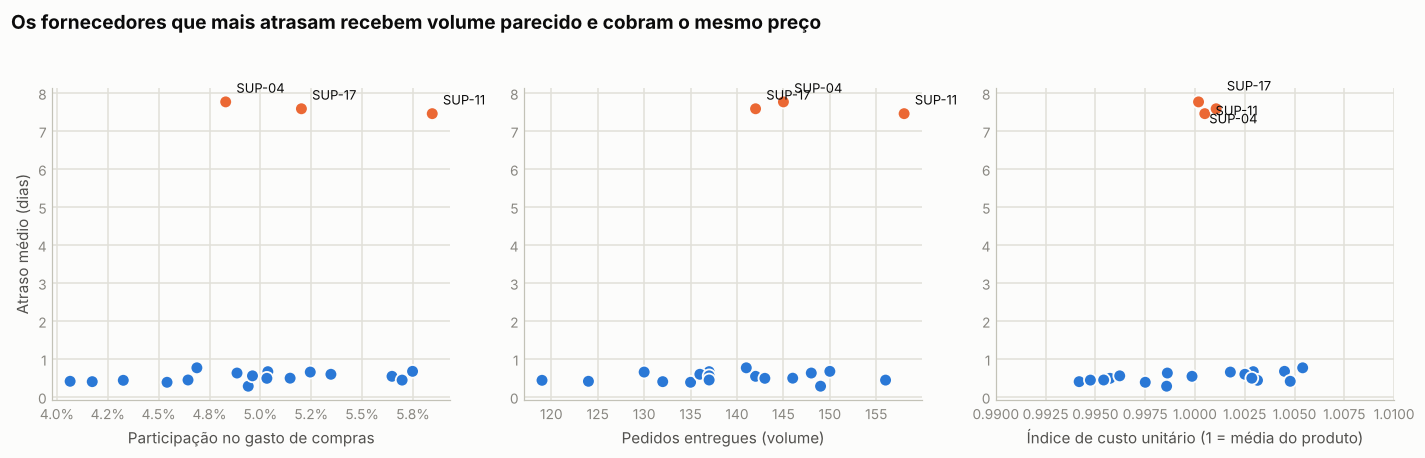


**Em uma frase:** os fornecedores que mais atrasam não são mais baratos, nem recebem menos pedidos, nem geram mais urgência.

- ✅ **Fato:** **não há "desconto por atraso"**: o preço pago por unidade é praticamente o mesmo em todos os fornecedores (índice entre 0,994 e 1,005, onde 1,00 é o preço médio do produto). Logo, não existe uma troca "preço menor × prazo pior" que justifique manter o mesmo volume com quem atrasa.
- ✅ **Fato:** **o volume não diminui com o mau desempenho:** os problemáticos recebem em média **148 pedidos** contra **139** dos demais (16% dos pedidos e 16% do gasto).
- ✅ **Fato:** **urgência:** 9,7% dos pedidos dos problemáticos são urgentes, contra 11,3% dos demais. Não há sinal de que a empresa "pague para correr" mais com eles.
- ✅ **Fato:** o **valor médio do pedido** é igual (0,137 mi vs 0,137 mi).
- 🔗 **Associação (frágil):** fornecedores com maior participação no gasto tendem a atrasar um pouco mais (em décimos de dia). Com só 20 fornecedores e muitos testes, tratamos como **hipótese a monitorar**, não como conclusão, e **não é causal** (o gasto depende do volume e do mix de produtos).
- **Custo financeiro do atraso: não mensurável.** A base não traz multas, frete urgente por atraso, custo de falta de produto nem juros de estoque. **Nenhum valor em reais é atribuído aos atrasos.**

<details><summary>🔧 Nota técnica</summary>

Atraso médio × participação no gasto: ρ de Spearman = +0,49 (p = 0,03) entre os 20 e +0,52 (p = 0,03) entre os 17 normais. Atraso × nº de pedidos: ρ = +0,33 (p = 0,16). Urgência: qui-quadrado, p = 0,34. Índice de preço = custo da linha ÷ custo médio do mesmo produto; os crônicos ficam em 1,000, 1,000 e 1,001.
</details>


In [18]:
pu = painel_exposicao_custo(T, ped)
f2 = f.set_index('fornecedor').join(pu.rename('idx_custo')).reset_index()
rho_g = stats.spearmanr(f2.atraso_medio, f2.share_gasto); rho_v = stats.spearmanr(f2.atraso_medio, f2.pedidos); rho_c = stats.spearmanr(f2.atraso_medio, f2.idx_custo)
nc2 = f2[~f2.cronico]; rho_g_nc = stats.spearmanr(nc2.atraso_medio, nc2.share_gasto); rho_v_nc = stats.spearmanr(nc2.atraso_medio, nc2.pedidos)
exp_c = ent.groupby('cronico').expedited.mean(); p_exp = float(stats.chi2_contingency(pd.crosstab(ent.cronico, ent.expedited))[1])
val_c = ent.groupby('cronico').valor.mean()
K.update(rho_gasto=(float(rho_g.statistic), float(rho_g.pvalue)), rho_gasto_nc=(float(rho_g_nc.statistic), float(rho_g_nc.pvalue)),
         rho_vol=(float(rho_v.statistic), float(rho_v.pvalue)), rho_custo=(float(rho_c.statistic), float(rho_c.pvalue)),
         idx_custo_cron=[float(v) for v in f2[f2.cronico].idx_custo], idx_custo_min=float(f2.idx_custo.min()), idx_custo_max=float(f2.idx_custo.max()),
         exp_cron=float(exp_c[True]), exp_nao=float(exp_c[False]), p_exp=p_exp, valor_cron=float(val_c[True]), valor_nao=float(val_c[False]),
         cron_pedidos_med=float(f2[f2.cronico].pedidos.mean()), nao_pedidos_med=float(f2[~f2.cronico].pedidos.mean()))

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, (col, xl, fmt) in zip(axs, [('share_gasto', 'Participação no gasto de compras', 'p'), ('pedidos', 'Pedidos entregues (volume)', 'n'), ('idx_custo', 'Índice de custo unitário (1 = média do produto)', 'c')]):
    ax.scatter(f2[col] * (100 if fmt == 'p' else 1), f2.atraso_medio, s=70, c=[CRON_COR(v) for v in f2.cronico], edgecolor=SURFACE, lw=1.2)
    for k_, r in enumerate(f2[f2.cronico].sort_values(col).itertuples()): ax.annotate(r.fornecedor, (getattr(r, col) * (100 if fmt == 'p' else 1), r.atraso_medio), xytext=(7, -14 + 13 * (k_ % 3) if fmt == 'c' else 6), textcoords='offset points', fontsize=8.5)
    estilo(ax, 'both'); ax.set_xlabel(xl)
    if fmt == 'p': ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
    if fmt == 'c': ax.set_xlim(.99, 1.01)
axs[0].set_ylabel('Atraso médio (dias)')
fig.suptitle('Os fornecedores que mais atrasam recebem volume parecido e cobram o mesmo preço', x=.01, ha='left', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout(); salvar(fig, 'a5_atraso_custo_volume'); plt.show()
display(Markdown(f"""
**Em uma frase:** os fornecedores que mais atrasam não são mais baratos, nem recebem menos pedidos, nem geram mais urgência.

- ✅ **Fato:** **não há "desconto por atraso"**: o preço pago por unidade é praticamente o mesmo em todos os fornecedores (índice entre {num(K['idx_custo_min'],3)} e {num(K['idx_custo_max'],3)}, onde 1,00 é o preço médio do produto). Logo, não existe uma troca "preço menor × prazo pior" que justifique manter o mesmo volume com quem atrasa.
- ✅ **Fato:** **o volume não diminui com o mau desempenho:** os problemáticos recebem em média **{num(K['cron_pedidos_med'],0)} pedidos** contra **{num(K['nao_pedidos_med'],0)}** dos demais ({pct(K['cron_share_pedidos'],0)} dos pedidos e {pct(K['cron_share_gasto'],0)} do gasto).
- ✅ **Fato:** **urgência:** {pct(K['exp_cron'],1)} dos pedidos dos problemáticos são urgentes, contra {pct(K['exp_nao'],1)} dos demais. Não há sinal de que a empresa "pague para correr" mais com eles.
- ✅ **Fato:** o **valor médio do pedido** é igual ({mi(K['valor_cron'],3)} mi vs {mi(K['valor_nao'],3)} mi).
- 🔗 **Associação (frágil):** fornecedores com maior participação no gasto tendem a atrasar um pouco mais (em décimos de dia). Com só 20 fornecedores e muitos testes, tratamos como **hipótese a monitorar**, não como conclusão, e **não é causal** (o gasto depende do volume e do mix de produtos).
- **Custo financeiro do atraso: não mensurável.** A base não traz multas, frete urgente por atraso, custo de falta de produto nem juros de estoque. **Nenhum valor em reais é atribuído aos atrasos.**

<details><summary>🔧 Nota técnica</summary>

Atraso médio × participação no gasto: ρ de Spearman = {sg(K['rho_gasto'][0],2)} (p = {num(K['rho_gasto'][1],2)}) entre os 20 e {sg(K['rho_gasto_nc'][0],2)} (p = {num(K['rho_gasto_nc'][1],2)}) entre os 17 normais. Atraso × nº de pedidos: ρ = {sg(K['rho_vol'][0],2)} (p = {num(K['rho_vol'][1],2)}). Urgência: qui-quadrado, p = {num(K['p_exp'],2)}. Índice de preço = custo da linha ÷ custo médio do mesmo produto; os crônicos ficam em {num(K['idx_custo_cron'][0],3)}, {num(K['idx_custo_cron'][1],3)} e {num(K['idx_custo_cron'][2],3)}.
</details>
"""))

### 5.2 Qualidade (itens rejeitados)

In [19]:
rej = ent.groupby('cronico').apply(lambda d: d.qtd_rej.sum() / d.qtd_rec.sum())
ent['rej_taxa'] = ent.qtd_rej / ent.qtd_rec
p_rej = float(stats.mannwhitneyu(ent[ent.cronico].rej_taxa, ent[~ent.cronico].rej_taxa).pvalue)
rho_rej = stats.spearmanr(ent.atraso, ent.rej_taxa)
K.update(rej_cron=float(rej[True]), rej_nao=float(rej[False]), p_rej=p_rej, rho_rej=(float(rho_rej.statistic), float(rho_rej.pvalue)))
display(Markdown(f"""
**Em uma frase:** quem atrasa não entrega pior qualidade; o problema é de **prazo**, não de conformidade.

- ✅ **Fato:** a **taxa de rejeição** é a mesma: **{pct(K['rej_cron'],2)}** nos problemáticos contra **{pct(K['rej_nao'],2)}** nos demais.

<details><summary>🔧 Nota técnica</summary>

Mann–Whitney por pedido: p = {num(p_rej,2)}. Correlação entre atraso e rejeição no pedido: ρ = {sg(K['rho_rej'][0],3)} (p = {num(K['rho_rej'][1],2)}).
</details>
"""))


**Em uma frase:** quem atrasa não entrega pior qualidade; o problema é de **prazo**, não de conformidade.

- ✅ **Fato:** a **taxa de rejeição** é a mesma: **2,41%** nos problemáticos contra **2,42%** nos demais.

<details><summary>🔧 Nota técnica</summary>

Mann–Whitney por pedido: p = 0,59. Correlação entre atraso e rejeição no pedido: ρ = +0,020 (p = 0,30).
</details>


### 5.3 Falta de produto e atendimento ao cliente

Três formas de procurar efeito:
1. **Colchão de estoque:** quantos dias de demanda o ponto de reposição (ROP) cobre? Se o atraso for maior que o colchão, existe risco de faltar produto (hipótese).
2. **Produto × mês:** meses com mais entregas graves de fornecedor são seguidos de mais falta de produto?
3. **Atendimento ao cliente:** a pontualidade das remessas ao cliente piora quando os fornecedores atrasam mais?

**Limite do desenho dos dados:** todos os 40 produtos são comprados dos **mesmos 20 fornecedores**, e não há ligação entre um pedido de compra e uma remessa ao cliente. Isso torna **difícil** enxergar efeitos, mesmo que existam.

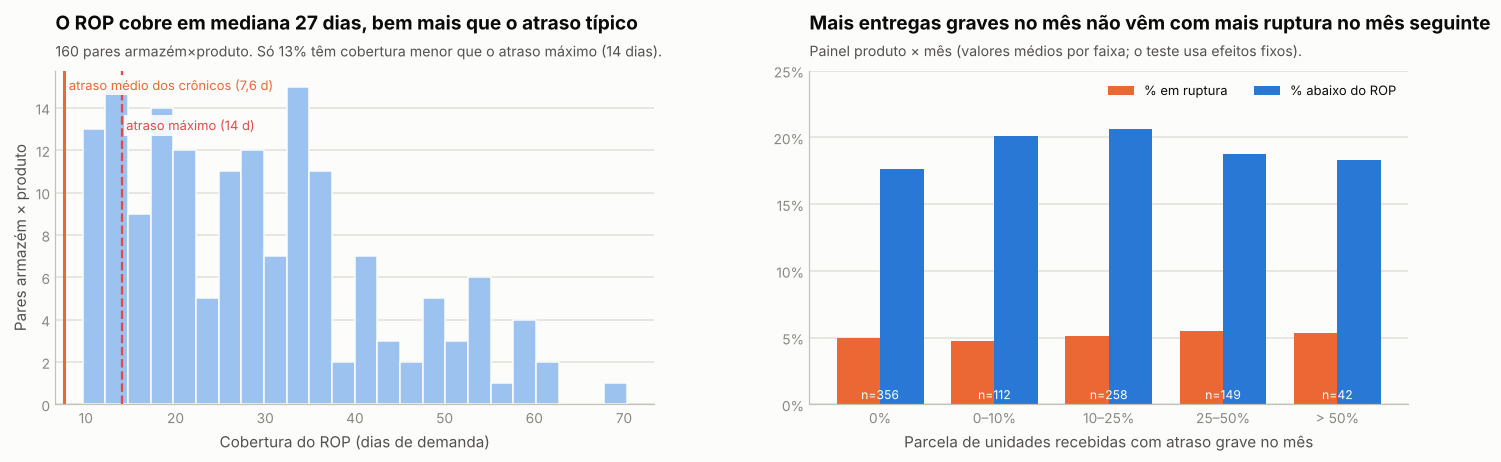


**Em uma frase:** não encontramos evidência de que os atrasos tenham causado falta de produto ou piorado o atendimento, mas os dados dificilmente conseguiriam mostrar isso.

- 💡 **Hipótese (risco potencial):** o ponto de reposição cobre cerca de **27 dias de demanda** (de 10 a 70). O atraso médio dos problemáticos (7,6 dias) é **menor** que esse colchão em 100% dos casos. O risco estaria nos atrasos de 10 a 14 dias, que superam o colchão em 13% dos pares armazém × produto. *É uma conta de cobertura, não uma medição de falta de produto.*
- 🔗 **Associação (sem evidência):** meses com mais entregas graves **não** foram seguidos de mais falta de produto: a diferença estimada é de +1,6 ponto percentual, num intervalo de −1,4 a +4,6 (que inclui o zero).
- 🔗 **Associação (sem evidência):** a pontualidade das remessas aos clientes (85,9% no geral) **não** acompanha a parcela de entregas graves de fornecedores no mês.
- **Como ler:** *não achar um efeito não é o mesmo que provar que ele não existe.* Com a limitação acima, **o desenho dos dados dificilmente detectaria o efeito, mesmo que ele exista**. A conclusão correta é "impacto sobre estoque e atendimento **não comprovado** nesta base".
- 💡 **Hipótese:** planejamento operacional e experiência do cliente: sem dados diretos, ficam como pontos a investigar (replanejamento de produção, reservas de estoque, devoluções).

<details><summary>🔧 Nota técnica</summary>

Painel produto × mês (917 observações; efeitos fixos de produto e de mês; erros agrupados por produto): ruptura +1,6 p.p. (p = 0,29); itens abaixo do ROP +1,0 p.p. (p = 0,70). Série mensal (24 pontos): ρ com ruptura = +0,11 (p = 0,62); ρ com nível de serviço = −0,11 (p = 0,62).
</details>


In [20]:
cob = cobertura_rop(T)
cron_med = float(np.mean(K['cron_sev'])); max_atraso = K['atraso_max']
K.update(cob_med=float(cob.median()), cob_min=float(cob.min()), cob_p25=float(cob.quantile(.25)), cob_max=float(cob.max()),
         cob_lt_cron=float((cob < cron_med).mean()), cob_lt_max=float((cob < max_atraso).mean()), n_pares=len(cob))

pn = painel_produto_mes(T, ped).dropna(subset=['sh_grave', 'rup', 'abx'])
res_painel = {}
for y, nome in [('rup', 'ruptura'), ('abx', 'abaixo do ROP')]:
    m = smf.ols(f'{y} ~ sh_grave + C(product_id) + C(mes_ent)', data=pn).fit(cov_type='cluster', cov_kwds={'groups': pn.product_id})
    res_painel[nome] = (float(m.params['sh_grave']), float(m.pvalues['sh_grave']), float(m.conf_int().loc['sh_grave', 0]), float(m.conf_int().loc['sh_grave', 1]))
K['painel'] = res_painel; K['painel_n'] = len(pn)
agm = pn.groupby('mes_ent').apply(lambda d: pd.Series({'sh': d.un_grave.sum() / d.un.sum(), 'rup': d.rup.mean(), 'abx': d.abx.mean()}))
K['rho_mensal_rup'] = tuple(float(v) for v in stats.spearmanr(agm.sh, agm.rup)); K['rho_mensal_abx'] = tuple(float(v) for v in stats.spearmanr(agm.sh, agm.abx))
sh_ = T['shipment'].assign(mes=T['shipment'].ship_date.dt.to_period('M').astype(str)); ot = sh_.groupby('mes').on_time_flag.mean()
j = agm.join(ot.rename('on_time'), how='inner'); K['rho_servico'] = tuple(float(v) for v in stats.spearmanr(j.sh, j.on_time)); K['on_time_geral'] = float(sh_.on_time_flag.mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.hist(cob, bins=24, color='#9cc3f0', edgecolor=SURFACE)
ax1.axvline(cron_med, color=ORANGE, lw=2); ax1.axvline(max_atraso, color=RED, lw=1.5, ls='--')
ax1.text(cron_med + .5, ax1.get_ylim()[1] * .98, f'atraso médio dos crônicos ({num(cron_med,1)} d)', color=ORANGE, fontsize=8.5, va='top', ha='left', bbox=dict(fc=SURFACE, ec='none', alpha=.9, pad=1.5))
ax1.text(max_atraso + .5, ax1.get_ylim()[1] * .86, f'atraso máximo ({max_atraso} d)', color=RED, fontsize=8.5, va='top', ha='left', bbox=dict(fc=SURFACE, ec='none', alpha=.9, pad=1.5))
estilo(ax1); ax1.set_xlabel('Cobertura do ROP (dias de demanda)'); ax1.set_ylabel('Pares armazém × produto')
titulo(ax1, f"O ROP cobre em mediana {num(K['cob_med'],0)} dias, bem mais que o atraso típico", f"{K['n_pares']} pares armazém×produto. Só {pct(K['cob_lt_max'],0)} têm cobertura menor que o atraso máximo ({max_atraso} dias).")
pn['faixa'] = pd.cut(pn.sh_grave, [-.001, 0, .1, .25, .5, 1.0], labels=['0%', '0–10%', '10–25%', '25–50%', '> 50%'])
g = pn.groupby('faixa', observed=True).agg(rup=('rup', 'mean'), abx=('abx', 'mean'), n=('rup', 'size'))
xx = np.arange(len(g)); ax2.bar(xx - .19, g.rup * 100, .38, color=ORANGE, label='% em ruptura'); ax2.bar(xx + .19, g.abx * 100, .38, color=BLUE, label='% abaixo do ROP')
for i, n in enumerate(g.n): ax2.text(i, 0.4, f'n={n}', ha='center', fontsize=8, color='white')
ax2.set_xticks(xx); ax2.set_xticklabels(g.index); estilo(ax2); ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax2.yaxis.set_major_locator(mtick.MultipleLocator(5)); ax2.legend(fontsize=8.5, loc='upper right', ncol=2)
ax2.set_ylim(0, 25); ax2.set_xlabel('Parcela de unidades recebidas com atraso grave no mês'); titulo(ax2, 'Mais entregas graves no mês não vêm com mais ruptura no mês seguinte', 'Painel produto × mês (valores médios por faixa; o teste usa efeitos fixos).')
plt.tight_layout(); salvar(fig, 'a6_estoque_exposicao'); plt.show()
pr_, pa_ = K['painel']['ruptura'], K['painel']['abaixo do ROP']
display(Markdown(f"""
**Em uma frase:** não encontramos evidência de que os atrasos tenham causado falta de produto ou piorado o atendimento, mas os dados dificilmente conseguiriam mostrar isso.

- 💡 **Hipótese (risco potencial):** o ponto de reposição cobre cerca de **{num(K['cob_med'],0)} dias de demanda** (de {num(K['cob_min'],0)} a {num(K['cob_max'],0)}). O atraso médio dos problemáticos ({num(cron_med,1)} dias) é **menor** que esse colchão em {pct(1-K['cob_lt_cron'],0)} dos casos. O risco estaria nos atrasos de 10 a 14 dias, que superam o colchão em {pct(K['cob_lt_max'],0)} dos pares armazém × produto. *É uma conta de cobertura, não uma medição de falta de produto.*
- 🔗 **Associação (sem evidência):** meses com mais entregas graves **não** foram seguidos de mais falta de produto: a diferença estimada é de {sg(pr_[0]*100,1)} ponto percentual, num intervalo de {sg(pr_[2]*100,1)} a {sg(pr_[3]*100,1)} (que inclui o zero).
- 🔗 **Associação (sem evidência):** a pontualidade das remessas aos clientes ({pct(K['on_time_geral'],1)} no geral) **não** acompanha a parcela de entregas graves de fornecedores no mês.
- **Como ler:** *não achar um efeito não é o mesmo que provar que ele não existe.* Com a limitação acima, **o desenho dos dados dificilmente detectaria o efeito, mesmo que ele exista**. A conclusão correta é "impacto sobre estoque e atendimento **não comprovado** nesta base".
- 💡 **Hipótese:** planejamento operacional e experiência do cliente: sem dados diretos, ficam como pontos a investigar (replanejamento de produção, reservas de estoque, devoluções).

<details><summary>🔧 Nota técnica</summary>

Painel produto × mês ({num(K['painel_n'])} observações; efeitos fixos de produto e de mês; erros agrupados por produto): ruptura {sg(pr_[0]*100,1)} p.p. (p = {num(pr_[1],2)}); itens abaixo do ROP {sg(pa_[0]*100,1)} p.p. (p = {num(pa_[1],2)}). Série mensal (24 pontos): ρ com ruptura = {sg(K['rho_mensal_rup'][0],2)} (p = {num(K['rho_mensal_rup'][1],2)}); ρ com nível de serviço = {sg(K['rho_servico'][0],2)} (p = {num(K['rho_servico'][1],2)}).
</details>
"""))

### 5.4 Os fornecedores "estratégicos" são mais pontuais?

Não há um campo "estratégico" na base. Comparamos três definições razoáveis e transparentes: **fonte única** (dependência), **tier A** (classificação do fornecedor) e **maior relevância financeira** (25% de maior gasto).

In [21]:
fx = f.copy(); K['cron_maior_gasto'] = f[f.cronico].sort_values('gasto').iloc[-1].fornecedor; lim_g = fx.gasto.quantile(.75)
defs = {'Fonte única': fx.single_source == 1, 'Tier A': fx.tier == 'A', 'Top 25% do gasto': fx.gasto >= lim_g}
linhas = []
for nome, mask in defs.items():
    for rot, m in [('estratégico', mask), ('não estratégico', ~mask)]:
        sub = fx[m]; e_ = ent[ent.fornecedor.isin(sub.fornecedor)]
        linhas.append({'definição': nome, 'grupo': rot, 'fornecedores': len(sub), 'crônicos no grupo': int(sub.cronico.sum()), '% atrasado': e_.atrasado.mean(),
                       'atraso médio (dias)': e_.atraso.mean(), '% atraso grave': e_.grave.mean()})
est = pd.DataFrame(linhas); K['est'] = est.to_dict('records')
display(est.style.hide(axis='index').format({'% atrasado': '{:.1%}', 'atraso médio (dias)': '{:.2f}', '% atraso grave': '{:.1%}'}))
display(Markdown(f"""
**Em uma frase:** nenhuma definição de "fornecedor estratégico" protege contra o atraso.

- ✅ **Fato:** dos {int(fx.single_source.sum())} fornecedores de **fonte única**, {int(fx[fx.single_source==1].cronico.sum())} é problemático; eles atrasam em média {num(ent[ent.is_single_source==1].atraso.mean(),1)} dia. Existe risco de dependência ({pct(fx[fx.single_source==1].share_gasto.sum(),0)} do gasto sem alternativa), mas **hoje isso não vem acompanhado de atraso**.
- ✅ **Fato:** os três problemáticos são de tiers diferentes ({', '.join(f'{n} = tier {t_}' for n, t_ in zip(K['cron_nomes'], K['cron_tier']))}), e {fx.loc[fx.rating.idxmax(),'fornecedor']} tem a maior nota de qualidade da base ({num(fx.rating.max(),2)}). **Tier e nota de qualidade não protegem contra o atraso.**
- O problemático de **maior gasto** é **{fx[fx.cronico].sort_values('gasto').iloc[-1].fornecedor}** (tier {fx[fx.cronico].sort_values('gasto').iloc[-1].tier}, prazo prometido de {num(fx[fx.cronico].sort_values('gasto').iloc[-1].prazo_prometido,0)} dias): é onde o peso financeiro e o atraso mais se encontram.
"""))

definição,grupo,fornecedores,crônicos no grupo,% atrasado,atraso médio (dias),% atraso grave
Fonte única,estratégico,5,0,50.1%,0.53,0.0%
Fonte única,não estratégico,15,3,61.0%,2.03,19.3%
Tier A,estratégico,6,1,57.4%,1.68,14.9%
Tier A,não estratégico,14,2,58.5%,1.63,14.1%
Top 25% do gasto,estratégico,5,1,61.6%,2.03,19.5%
Top 25% do gasto,não estratégico,15,2,56.9%,1.51,12.5%



**Em uma frase:** nenhuma definição de "fornecedor estratégico" protege contra o atraso.

- ✅ **Fato:** dos 5 fornecedores de **fonte única**, 0 é problemático; eles atrasam em média 0,5 dia. Existe risco de dependência (26% do gasto sem alternativa), mas **hoje isso não vem acompanhado de atraso**.
- ✅ **Fato:** os três problemáticos são de tiers diferentes (SUP-04 = tier B, SUP-17 = tier A, SUP-11 = tier C), e SUP-17 tem a maior nota de qualidade da base (4,97). **Tier e nota de qualidade não protegem contra o atraso.**
- O problemático de **maior gasto** é **SUP-11** (tier C, prazo prometido de 35 dias): é onde o peso financeiro e o atraso mais se encontram.


### 5.5 Resumo: o que foi medido e o que não foi

In [22]:
sint = pd.DataFrame([
    ('Custo (preço unitário)', 'Medido', f"Sem relação: índice de custo entre {num(K['idx_custo_min'],3)} e {num(K['idx_custo_max'],3)} em todos os fornecedores".replace('.', ','), 'FATO'),
    ('Volume de pedidos', 'Medido', f"Crônicos recebem volume parecido ({pct(K['cron_share_pedidos'],0)} dos pedidos)", 'FATO'),
    ('Urgência / expedição', 'Medido', f"Sem mais pedidos urgentes nos crônicos ({pct(K['exp_cron'],1)} vs {pct(K['exp_nao'],1)})", 'FATO'),
    ('Rejeição (qualidade)', 'Medido', f"Mesma taxa de rejeição ({pct(K['rej_cron'],1)} vs {pct(K['rej_nao'],1)})", 'FATO'),
    ('Ruptura e disponibilidade', 'Testado, sem evidência', 'Painel produto×mês e série mensal sem associação detectável', 'ASSOCIAÇÃO (nula)'),
    ('Nível de serviço ao cliente', 'Testado, sem evidência', 'Sem ligação compra↔remessa; série mensal sem associação', 'ASSOCIAÇÃO (nula)'),
    ('Exposição de estoque (cobertura ROP)', 'Cálculo de cobertura', f"ROP cobre ~{num(K['cob_med'],0)} dias; atraso típico dos crônicos (~{num(float(np.mean(K['cron_sev'])),1)}) fica abaixo; só caudas de 10–14 dias superam em {pct(K['cob_lt_max'],0)} dos pares", 'HIPÓTESE'),
    ('Custo financeiro / multas / ruptura em R$', 'Não mensurável', 'A base não tem esses dados', 'NÃO ATRIBUÍDO'),
    ('Planejamento operacional / experiência do cliente', 'Não mensurável', 'Sem dados diretos', 'HIPÓTESE'),
], columns=['dimensão', 'status', 'resultado', 'natureza'])
display(sint.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

dimensão,status,resultado,natureza
Custo (preço unitário),Medido,"Sem relação: índice de custo entre 0,994 e 1,005 em todos os fornecedores",FATO
Volume de pedidos,Medido,Crônicos recebem volume parecido (16% dos pedidos),FATO
Urgência / expedição,Medido,"Sem mais pedidos urgentes nos crônicos (9,7% vs 11,3%)",FATO
Rejeição (qualidade),Medido,"Mesma taxa de rejeição (2,4% vs 2,4%)",FATO
Ruptura e disponibilidade,"Testado, sem evidência",Painel produto×mês e série mensal sem associação detectável,ASSOCIAÇÃO (nula)
Nível de serviço ao cliente,"Testado, sem evidência",Sem ligação compra↔remessa; série mensal sem associação,ASSOCIAÇÃO (nula)
Exposição de estoque (cobertura ROP),Cálculo de cobertura,"ROP cobre ~27 dias; atraso típico dos crônicos (~7,6) fica abaixo; só caudas de 10–14 dias superam em 13% dos pares",HIPÓTESE
Custo financeiro / multas / ruptura em R$,Não mensurável,A base não tem esses dados,NÃO ATRIBUÍDO
Planejamento operacional / experiência do cliente,Não mensurável,Sem dados diretos,HIPÓTESE


## Capítulo 6 · Os casos extremos são erro ou realidade?

**Casos extremos** (*outliers*) são entregas ou pedidos muito fora do comum. A dúvida é: são **erros de digitação** (e deveriam ser corrigidos ou descartados) ou **acontecimentos reais** (e então são justamente o que queremos estudar)?

Regra do capítulo: **nada é apagado automaticamente**. Vários métodos sinalizam os casos, nós julgamos o que são e depois comparamos os resultados **com e sem** eles.

<details><summary>🔧 Nota técnica: métodos</summary>

IQR (limites de 1,5× e 3×), boxplots, escore z (|z| > 3), percentis P1/P99 e Isolation Forest (análise multivariada). Variáveis: atraso, tempo de entrega real, valor do pedido, quantidade de itens e frequência de atrasos por fornecedor.
</details>

**Pedidos (nível de pedido)**

variável,n,"limite inferior (1,5×IQR)","limite superior (1,5×IQR)","outliers 1,5×IQR","% 1,5×IQR",outliers 3×IQR,|z| > 3,P1,P99,máximo
Atraso (dias),2807,-7.00,9.00,122,4.35,0,51,-2.00,12.00,14.00
Tempo de entrega real (dias),2807,-6.50,37.50,203,7.23,0,0,5.00,45.94,49.00
Valor do pedido (= custo das linhas),2807,-168137.78,412866.70,74,2.64,12,36,2213.06,501787.57,859316.43
Itens (quantidade),2807,-1021.75,3724.25,34,1.21,0,21,98.00,3822.94,4885.00


**Fornecedores (nível de fornecedor, n = 20)**

variável,n,"limite inferior (1,5×IQR)","limite superior (1,5×IQR)","outliers 1,5×IQR","% 1,5×IQR",outliers 3×IQR,|z| > 3,P1,P99,máximo
% de atrasos por fornecedor,20,0.41,0.64,3,15.00,3,0,0.42,1.00,1.00
Severidade por fornecedor (dias),20,1.76,2.29,3,15.00,3,0,1.86,7.73,7.77


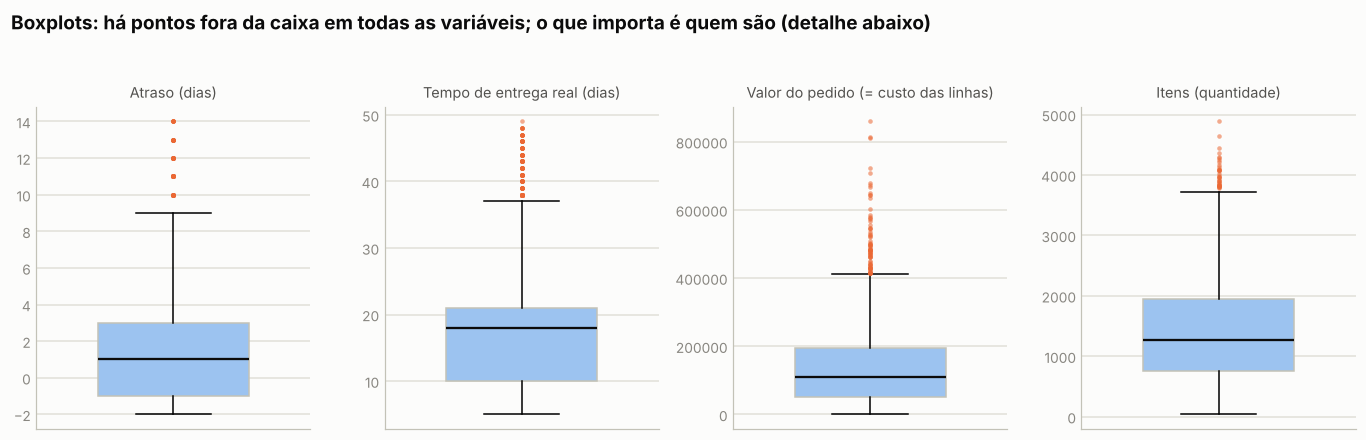

In [23]:
ent['tempo_entrega'] = ent.prazo_prometido + ent.atraso          # dias entre pedido e entrega real
cols_out = {'Atraso (dias)': 'atraso', 'Tempo de entrega real (dias)': 'tempo_entrega', 'Valor do pedido (= custo das linhas)': 'valor', 'Itens (quantidade)': 'itens'}
ro = resumo_outliers(ent, cols_out)
fo = resumo_outliers(f, {'% de atrasos por fornecedor': 'pct_atrasado', 'Severidade por fornecedor (dias)': 'severidade'})
K['out_atraso'] = ro.iloc[0].to_dict()
K['fo_pct_out'] = int(fo.iloc[0]['outliers 1,5×IQR']); K['fo_sev_out'] = int(fo.iloc[1]['outliers 1,5×IQR'])
display(Markdown('**Pedidos (nível de pedido)**')); display(ro.style.hide(axis='index').format(precision=2))
display(Markdown('**Fornecedores (nível de fornecedor, n = 20)**')); display(fo.style.hide(axis='index').format(precision=2))

fig, axs = plt.subplots(1, 4, figsize=(12.5, 3.8))
for ax, (nome, col) in zip(axs, cols_out.items()):
    ax.boxplot(ent[col], patch_artist=True, widths=.55, whis=1.5, boxprops=dict(facecolor='#9cc3f0', edgecolor=AXIS), medianprops=dict(color=INK, lw=1.5),
               flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec='none', alpha=.55))
    ax.set_title(nome, fontsize=9.5, color=INK2); ax.set_xticks([]); estilo(ax)
fig.suptitle('Boxplots: há pontos fora da caixa em todas as variáveis; o que importa é quem são (detalhe abaixo)', x=.01, ha='left', fontsize=12.5, fontweight='bold', y=1.04)
plt.tight_layout(); salvar(fig, 'a7_boxplots_outliers'); plt.show()

**Os 8 maiores atrasos da base**

po_id,fornecedor,prazo_prometido,atraso,atraso_rel,valor
59,SUP-17,7,14.000000,200%,"109,820"
1615,SUP-04,18,14.000000,78%,"133,835"
1114,SUP-11,35,14.000000,40%,"182,356"
2560,SUP-04,18,14.000000,78%,"5,039"
2664,SUP-04,18,14.000000,78%,"56,186"
2518,SUP-17,7,14.000000,200%,"112,937"
490,SUP-04,18,14.000000,78%,"232,046"
831,SUP-04,18,13.000000,72%,"114,925"


fornecedor,SUP-04,SUP-17,SUP-11
outliers de atraso (IQR),42,41,39


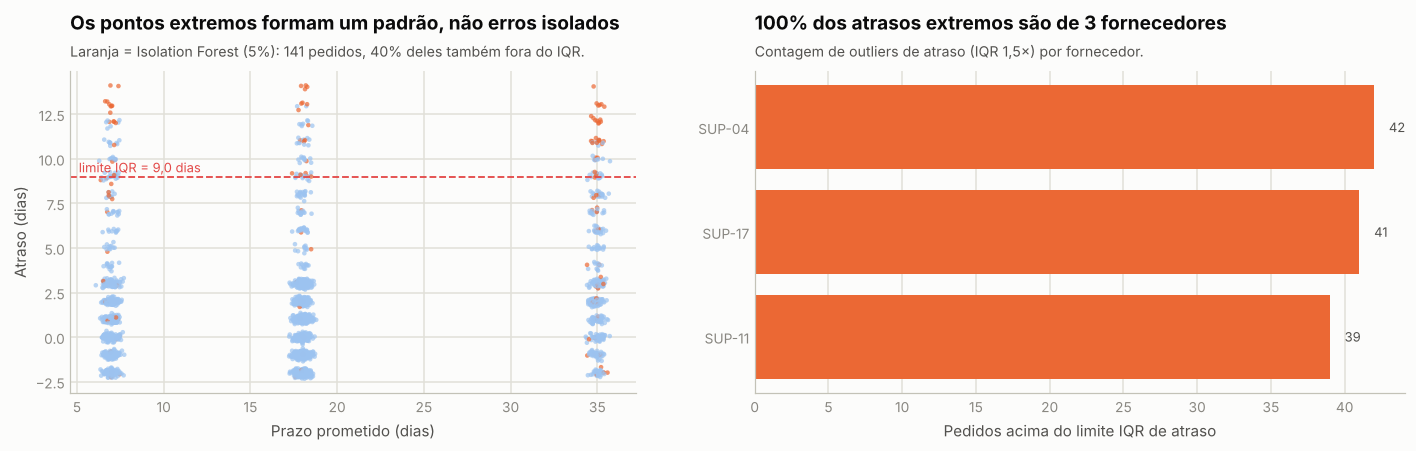

In [24]:
# --- Quem são os outliers de atraso? e são erro ou evento real? ---
lo_a, hi_a = limites_iqr(ent.atraso); K['hi_atraso'] = float(hi_a)
ent['out_iqr_atraso'] = ent.atraso > hi_a
n_out = int(ent.out_iqr_atraso.sum()); K['n_out_atraso'] = n_out; K['pct_out_atraso'] = n_out / len(ent)
por_forn = ent[ent.out_iqr_atraso].groupby('fornecedor').size().sort_values(ascending=False)
K['out_atraso_cron_share'] = float(por_forn[por_forn.index.isin(K['cron_nomes'])].sum() / n_out); K['out_atraso_forn'] = por_forn.to_dict()
# coerência das datas dos registros extremos (indício de erro de digitação seria entrega antes do pedido, datas fora do período, etc.)
ext = T['purchase_order'].merge(ent[ent.out_iqr_atraso][['po_id']], on='po_id')
K['ext_datas_ok'] = bool((ext.actual_delivery_date >= ext.order_date).all() and (ext.actual_delivery_date <= T['purchase_order'].actual_delivery_date.max()).all())
K['ext_status_ok'] = bool((ext.status == 'Delivered').all())
K['ext_rel_max'] = float(ent[ent.out_iqr_atraso].atraso_rel.max())

# Isolation Forest (multivariado: atraso, prazo, valor, itens), contaminação 5% = parâmetro de sensibilidade, não 'taxa verdadeira'
iso = isolation(ped, 0.05)
K['iso_n'] = int(iso.iso_outlier.sum()); K['iso_cron_share'] = float(iso[iso.iso_outlier].fornecedor.isin(K['cron_nomes']).mean())
K['iso_overlap'] = float(iso[iso.iso_outlier].po_id.isin(ent[ent.out_iqr_atraso].po_id).mean())
K['iso_atraso_med'] = float(iso[iso.iso_outlier].atraso.median())
# valor: eventos extremos de valor ocorrem em quais fornecedores?
lo_v, hi_v = limites_iqr(ent.valor); K['n_out_valor'] = int((ent.valor > hi_v).sum()); K['hi_valor'] = float(hi_v); K['out_valor_cron_share'] = float(ent[ent.valor > hi_v].fornecedor.isin(K['cron_nomes']).mean())
lo_i, hi_i = limites_iqr(ent.itens); K['n_out_itens'] = int((ent.itens > hi_i).sum()); K['hi_itens'] = float(hi_i)
K['rho_valor_atraso'] = float(stats.spearmanr(ent.valor, ent.atraso).statistic)
K['z3_atraso'] = int(((ent.atraso - ent.atraso.mean()).abs() / ent.atraso.std() > 3).sum())
top = ent.sort_values('atraso', ascending=False).head(8)[['po_id', 'fornecedor', 'prazo_prometido', 'atraso', 'atraso_rel', 'valor']]
display(Markdown('**Os 8 maiores atrasos da base**')); display(top.style.hide(axis='index').format({'atraso_rel': '{:.0%}', 'valor': '{:,.0f}'}))
display(por_forn.rename('outliers de atraso (IQR)').to_frame().T)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1, 1.15]})
cores = np.where(iso.iso_outlier, ORANGE, '#9cc3f0')
ax1.scatter(iso.prazo_prometido + np.random.default_rng(SEED).normal(0, .25, len(iso)), iso.atraso + np.random.default_rng(SEED + 1).normal(0, .12, len(iso)), c=cores, s=9, alpha=.7, edgecolor='none')
ax1.axhline(hi_a, color=RED, lw=1.2, ls='--'); ax1.text(ax1.get_xlim()[0] + .5, hi_a + .25, f'limite IQR = {num(hi_a,1)} dias', color=RED, fontsize=8.5)
estilo(ax1, 'both'); ax1.set_xlabel('Prazo prometido (dias)'); ax1.set_ylabel('Atraso (dias)')
titulo(ax1, 'Os pontos extremos formam um padrão, não erros isolados', f"Laranja = Isolation Forest (5%): {K['iso_n']} pedidos, {pct(K['iso_overlap'],0)} deles também fora do IQR.")
orde = por_forn.sort_values()
ax2.barh(orde.index, orde.values, color=[ORANGE if s in K['cron_nomes'] else '#9cc3f0' for s in orde.index]); estilo(ax2, 'x')
for i, v in enumerate(orde.values): ax2.text(v + 1, i, str(v), va='center', fontsize=8.5, color=INK2)
ax2.set_xlabel('Pedidos acima do limite IQR de atraso')
titulo(ax2, f"{pct(K['out_atraso_cron_share'],0)} dos atrasos extremos são de 3 fornecedores", 'Contagem de outliers de atraso (IQR 1,5×) por fornecedor.')
plt.tight_layout(); salvar(fig, 'a8_isolation_forest'); plt.show()

In [25]:
# --- Comparação COM e SEM outliers (nada é removido da base; é um teste de sensibilidade) ---
def snap(d):
    fm = metricas_fornecedor(d); return fm, pd.Series(z_modificado(fm.severidade.values) > 3.5, index=fm.index)
sem = ped[~ped.po_id.isin(ent[ent.out_iqr_atraso].po_id)]
sem_iso = ped[~ped.po_id.isin(iso[iso.iso_outlier].po_id)]
lin = []
for rot, d in [('Com todos os pedidos', ped), ('Sem outliers IQR de atraso', sem), ('Sem sinalizados pelo Isolation Forest', sem_iso)]:
    e_ = d[d.entregue]; fm, cr = snap(d)
    lin.append({'cenário': rot, 'pedidos': len(e_), '% atrasado': e_.atrasado.mean(), 'atraso médio': e_.atraso.mean(), 'atraso mediano': e_.atraso.median(),
                'desvio padrão': e_.atraso.std(), 'fornecedores crônicos (z>3,5)': ', '.join(sorted(fm[cr.values].fornecedor))})
cmp_ = pd.DataFrame(lin); K['cmp_out'] = cmp_.to_dict('records')
K['robusto_cronicos'] = bool(cmp_['fornecedores crônicos (z>3,5)'].nunique() == 1)
display(cmp_.style.hide(axis='index').format({'% atrasado': '{:.1%}', 'atraso médio': '{:.2f}', 'atraso mediano': '{:.1f}', 'desvio padrão': '{:.2f}'}))

cenário,pedidos,% atrasado,atraso médio,atraso mediano,desvio padrão,"fornecedores crônicos (z>3,5)"
Com todos os pedidos,2807,58.2%,1.64,1.0,3.25,"SUP-04, SUP-11, SUP-17"
Sem outliers IQR de atraso,2685,56.3%,1.20,1.0,2.54,"SUP-04, SUP-11, SUP-17"
Sem sinalizados pelo Isolation Forest,2666,56.8%,1.37,1.0,2.86,"SUP-04, SUP-11, SUP-17"


In [26]:
c0, c1 = K['cmp_out'][0], K['cmp_out'][1]
display(Markdown(f"""
### Erro ou realidade? O que concluímos

**Em uma frase:** os casos extremos de atraso são **acontecimentos reais, não erros**, e apagá-los esconderia o problema.

| Variável | O que encontramos | Erro ou realidade? | Decisão |
|---|---|---|---|
| **Atraso** | {K['n_out_atraso']} pedidos ({pct(K['pct_out_atraso'],1)}) com mais de {num(K['hi_atraso'],0)} dias de atraso | **Realidade.** As datas fazem sentido (entrega depois do pedido, status "entregue") e {pct(K['out_atraso_cron_share'],0)} vêm dos 3 fornecedores problemáticos | **Manter:** é o fenômeno estudado |
| **Valor do pedido** | {K['n_out_valor']} pedidos acima de {num(K['hi_valor'],0)} | **Pedidos grandes e plausíveis.** Só {pct(K['out_valor_cron_share'],0)} são dos problemáticos (que somam {pct(K['cron_share_pedidos'],0)} dos pedidos), e o valor não tem relação com o atraso | **Manter** |
| **Quantidade de itens** | {K['n_out_itens']} pedidos acima de {num(K['hi_itens'],0)} unidades | Pedidos grandes e plausíveis | **Manter** |
| **% de atrasos por fornecedor** | {K['fo_pct_out']} fornecedores muito acima dos demais | São os 3 problemáticos (atrasam em 100% das entregas; os outros, no máximo ~{pct(K['nao_pct_max'],0)}) | **Foco de gestão** |
| **Gravidade por fornecedor** | {K['fo_sev_out']} fornecedores | Realidade, persistente nos 24 meses | **Foco de gestão** |

- ✅ **Fato:** se apagássemos os atrasos extremos, o atraso médio cairia de **{num(c0['atraso médio'],2)}** para **{num(c1['atraso médio'],2)}** dia. Ou seja, "limpar" esconderia a maior parte do problema: seria um erro de método.
- ✅ **Fato:** os fornecedores problemáticos são **os mesmos** com e sem os casos extremos ({'sim' if K['robusto_cronicos'] else 'não'}): a conclusão não depende dessa escolha.
- **Segunda opinião:** o Isolation Forest (algoritmo que procura combinações incomuns de atraso, prazo, valor e quantidade) aponta {pct(K['iso_cron_share'],0)} de casos dos problemáticos, com atraso mediano de {num(K['iso_atraso_med'],0)} dias. Ele depende de um parâmetro que escolhemos (5%), então serve como **confirmação**, não como "taxa verdadeira de anomalias".

<details><summary>🔧 Nota técnica</summary>

Limite superior IQR (1,5×) do atraso: {num(K['hi_atraso'],1)} dias. Pedidos com |z| > 3: {K['z3_atraso']}. Desvio padrão do atraso: {num(c0['desvio padrão'],2)} (com todos) vs {num(c1['desvio padrão'],2)} (sem os extremos). Correlação (Spearman) entre valor e atraso: {sg(K['rho_valor_atraso'],2)}.
</details>
"""))


### Erro ou realidade? O que concluímos

**Em uma frase:** os casos extremos de atraso são **acontecimentos reais, não erros**, e apagá-los esconderia o problema.

| Variável | O que encontramos | Erro ou realidade? | Decisão |
|---|---|---|---|
| **Atraso** | 122 pedidos (4,3%) com mais de 9 dias de atraso | **Realidade.** As datas fazem sentido (entrega depois do pedido, status "entregue") e 100% vêm dos 3 fornecedores problemáticos | **Manter:** é o fenômeno estudado |
| **Valor do pedido** | 74 pedidos acima de 412.867 | **Pedidos grandes e plausíveis.** Só 19% são dos problemáticos (que somam 16% dos pedidos), e o valor não tem relação com o atraso | **Manter** |
| **Quantidade de itens** | 34 pedidos acima de 3.724 unidades | Pedidos grandes e plausíveis | **Manter** |
| **% de atrasos por fornecedor** | 3 fornecedores muito acima dos demais | São os 3 problemáticos (atrasam em 100% das entregas; os outros, no máximo ~57%) | **Foco de gestão** |
| **Gravidade por fornecedor** | 3 fornecedores | Realidade, persistente nos 24 meses | **Foco de gestão** |

- ✅ **Fato:** se apagássemos os atrasos extremos, o atraso médio cairia de **1,64** para **1,20** dia. Ou seja, "limpar" esconderia a maior parte do problema: seria um erro de método.
- ✅ **Fato:** os fornecedores problemáticos são **os mesmos** com e sem os casos extremos (sim): a conclusão não depende dessa escolha.
- **Segunda opinião:** o Isolation Forest (algoritmo que procura combinações incomuns de atraso, prazo, valor e quantidade) aponta 65% de casos dos problemáticos, com atraso mediano de 8 dias. Ele depende de um parâmetro que escolhemos (5%), então serve como **confirmação**, não como "taxa verdadeira de anomalias".

<details><summary>🔧 Nota técnica</summary>

Limite superior IQR (1,5×) do atraso: 9,0 dias. Pedidos com |z| > 3: 51. Desvio padrão do atraso: 3,25 (com todos) vs 2,54 (sem os extremos). Correlação (Spearman) entre valor e atraso: +0,01.
</details>


## Capítulo 7 · Quais fornecedores são de maior risco?

### 7.1 Como classificamos o risco

Um fornecedor é de **alto risco** quando ele **atrasa muito mais dias que os outros** *e* **atrasa com mais frequência que a maioria**, numa diferença grande demais para ser coincidência. **Intermediário** = atende só um dos dois critérios. **Baixo** = nenhum. Não usamos cortes arbitrários ("acima de 5 dias"): os limites vêm dos próprios dados.

Essa classificação mede o **risco de atraso**. O peso financeiro de cada fornecedor aparece na matriz pelo tamanho da bolha.

<details><summary>🔧 Nota técnica: critérios</summary>

Gravidade atípica: atraso médio quando atrasa com escore z modificado (robusto) de Iglewicz–Hoaglin > 3,5. Frequência atípica: taxa de atraso acima da mediana dos fornecedores, em teste binomial unilateral com correção de Holm para 20 comparações (α = 5%).
</details>

In [27]:
r = classificar_risco(f); r['cronico'] = r.fornecedor.isin(K['cron_nomes'])
ordem_r = {'Alto': 0, 'Intermediário': 1, 'Baixo': 2}
K['risco_cont'] = r.risco.value_counts().reindex(['Alto', 'Intermediário', 'Baixo']).fillna(0).astype(int).to_dict()
K['risco_base_mediana'] = float(r.attrs['pct_base_mediana'])
mad = np.median(np.abs(r.severidade - r.severidade.median())); K['sev_limite'] = float(r.severidade.median() + 3.5 * mad / 0.6745)
tab = (r.assign(o=r.risco.map(ordem_r)).sort_values(['o', 'severidade'], ascending=[True, False])
        [['fornecedor', 'risco', 'tier', 'pais', 'pedidos', 'pct_atrasado', 'severidade', 'z_severidade', 'p_frequencia', 'share_gasto', 'single_source']])
tab.columns = ['fornecedor', 'risco', 'tier', 'país', 'pedidos', '% atrasado', 'severidade (dias)', 'z mod. severidade', 'p (freq., Holm)', '% do gasto', 'fonte única']
display(tab.head(8).style.hide(axis='index').format({'% atrasado': '{:.0%}', 'severidade (dias)': '{:.1f}', 'z mod. severidade': '{:.1f}', 'p (freq., Holm)': '{:.1e}', '% do gasto': '{:.1%}'})
        .map(lambda v: f'background-color:{"#fbd5c6" if v=="Alto" else "#fff1c9" if v=="Intermediário" else "#d9efe5"}' if v in ordem_r else '', subset=['risco']))
display(Markdown(f"Distribuição: **{K['risco_cont']['Alto']} alto · {K['risco_cont']['Intermediário']} intermediário · {K['risco_cont']['Baixo']} baixo**. Limite de gravidade = {num(K['sev_limite'],1)} dias de atraso médio quando atrasa; taxa de referência = {pct(K['risco_base_mediana'],0)}."))
# lista de observação: os 17 'baixo' mais próximos de algum critério
obs = r[r.risco == 'Baixo'].sort_values('z_severidade', ascending=False).head(3)[['fornecedor', 'severidade', 'z_severidade', 'pct_atrasado', 'p_frequencia']]
K['obs'] = obs.fornecedor.tolist(); K['obs_z'] = [float(v) for v in obs.z_severidade]; K['obs_p'] = [float(v) for v in obs.p_frequencia]
display(Markdown('**Fornecedores de baixo risco mais próximos de um limite (lista de observação)**')); display(obs.style.hide(axis='index').format({'severidade': '{:.2f}', 'z_severidade': '{:.2f}', 'pct_atrasado': '{:.0%}', 'p_frequencia': '{:.2f}'}))

fornecedor,risco,tier,país,pedidos,% atrasado,severidade (dias),z mod. severidade,"p (freq., Holm)",% do gasto,fonte única
SUP-04,Alto,B,USA,145,100%,7.8,54.4,5.2e-42,4.8%,0
SUP-17,Alto,A,Turkey,142,100%,7.6,52.7,3.7e-41,5.2%,0
SUP-11,Alto,C,India,158,100%,7.5,51.5,8.3e-46,5.8%,0
SUP-06,Baixo,A,USA,142,50%,2.1,0.8,1.0e+00,5.6%,0
SUP-18,Baixo,B,Poland,137,50%,2.1,0.6,1.0e+00,5.0%,0
SUP-10,Baixo,B,France,119,50%,2.1,0.4,1.0e+00,4.3%,0
SUP-08,Baixo,B,Germany,136,55%,2.1,0.4,1.0e+00,5.3%,0
SUP-01,Baixo,B,Turkey,148,53%,2.1,0.3,1.0e+00,4.9%,0


Distribuição: **3 alto · 0 intermediário · 17 baixo**. Limite de gravidade = 2,4 dias de atraso médio quando atrasa; taxa de referência = 51%.

**Fornecedores de baixo risco mais próximos de um limite (lista de observação)**

fornecedor,severidade,z_severidade,pct_atrasado,p_frequencia
SUP-06,2.13,0.81,50%,1.00
SUP-18,2.10,0.59,50%,1.00
SUP-10,2.08,0.41,50%,1.00


### 7.2 Grupos de fornecedores parecidos (segunda opinião)

Além das regras acima, pedimos ao computador para **agrupar fornecedores parecidos** (técnica K-Means), olhando 4 características: % de atrasos, gravidade, variação do atraso e atraso nos piores 10% das entregas (P90). A ideia é conferir se o agrupamento "descobre" os mesmos fornecedores, sem usar nossas regras.

<details><summary>🔧 Nota técnica</summary>

O número de grupos (k) foi escolhido pela *silhueta* (de −1 a 1; quanto maior, mais coesos e separados os grupos), testando k de 2 a 5.
</details>

In [28]:
g, tab_k = agrupar(r)
K['k_escolhido'] = int(g.grupo.nunique()); K['silhueta'] = float(tab_k.loc[tab_k.k == K['k_escolhido'], 'silhueta'].iloc[0])
K['silhuetas'] = {int(a): float(b) for a, b in zip(tab_k.k, tab_k.silhueta)}
sil345 = ', '.join('{:.2f}'.format(K['silhuetas'][k_]).replace('.', ',') for k_ in (3, 4, 5))
perfil = g.groupby('grupo').agg(fornecedores=('fornecedor', 'count'), pct_atrasado=('pct_atrasado', 'mean'), severidade=('severidade', 'mean'), desvio=('desvio', 'mean'), p90=('p90', 'mean'),
                                gasto=('share_gasto', 'sum'), membros=('fornecedor', lambda s: ', '.join(sorted(s)) if len(s) <= 4 else f'{len(s)} fornecedores'))
perfil.columns = ['fornecedores', '% atrasado', 'severidade (dias)', 'desvio padrão', 'P90 do atraso', '% do gasto', 'membros']
K['k_igual_risco'] = bool(set(g[g.grupo == 'Grupo 1'].fornecedor) == set(r[r.risco == 'Alto'].fornecedor))
display(tab_k.style.hide(axis='index').format({'inércia': '{:.1f}', 'silhueta': '{:.3f}'}))
display(perfil.style.format({'% atrasado': '{:.0%}', 'severidade (dias)': '{:.1f}', 'desvio padrão': '{:.1f}', 'P90 do atraso': '{:.1f}', '% do gasto': '{:.0%}'}))
display(Markdown(f"""
**Em uma frase:** o computador separou os fornecedores em dois grupos, e o grupo de maior atraso é exatamente o mesmo das nossas regras.

- ✅ **Fato:** a melhor divisão é em **{K['k_escolhido']} grupos** (silhueta {num(K['silhueta'],2)}). Com 3, 4 ou 5 grupos a qualidade cai ({sil345}): não existe um perfil "intermediário" de verdade.
- **Perfis em linguagem simples:** **Grupo 1** = "atrasa sempre e por muito tempo" (atrasa em ~100% das entregas, em média ~{num(perfil.loc['Grupo 1','severidade (dias)'],0)} dias). **Grupo 2** = "atrasa em cerca de metade das entregas, por pouco tempo e de forma imprevisível".
- ✅ **Fato:** o agrupamento chega **aos mesmos fornecedores** dos critérios de risco ({'sim' if K['k_igual_risco'] else 'não'}). As duas visões se confirmam.
"""))

k,inércia,silhueta
2,1.6,0.931
3,0.9,0.535
4,0.6,0.453
5,0.4,0.375


,fornecedores,% atrasado,severidade (dias),desvio padrão,P90 do atraso,% do gasto,membros
grupo,,,,,,,
Grupo 1,3,100%,7.6,3.1,11.7,16%,"SUP-04, SUP-11, SUP-17"
Grupo 2,17,50%,2.0,1.7,3.0,84%,17 fornecedores



**Em uma frase:** o computador separou os fornecedores em dois grupos, e o grupo de maior atraso é exatamente o mesmo das nossas regras.

- ✅ **Fato:** a melhor divisão é em **2 grupos** (silhueta 0,93). Com 3, 4 ou 5 grupos a qualidade cai (0,54, 0,45, 0,37): não existe um perfil "intermediário" de verdade.
- **Perfis em linguagem simples:** **Grupo 1** = "atrasa sempre e por muito tempo" (atrasa em ~100% das entregas, em média ~8 dias). **Grupo 2** = "atrasa em cerca de metade das entregas, por pouco tempo e de forma imprevisível".
- ✅ **Fato:** o agrupamento chega **aos mesmos fornecedores** dos critérios de risco (sim). As duas visões se confirmam.


### 7.3 Matriz de risco

Cada bolha é um fornecedor: quanto mais **para a direita** (atrasa com mais frequência) e **para cima** (atrasa por mais dias), pior. O tamanho da bolha é a participação no gasto de compras.

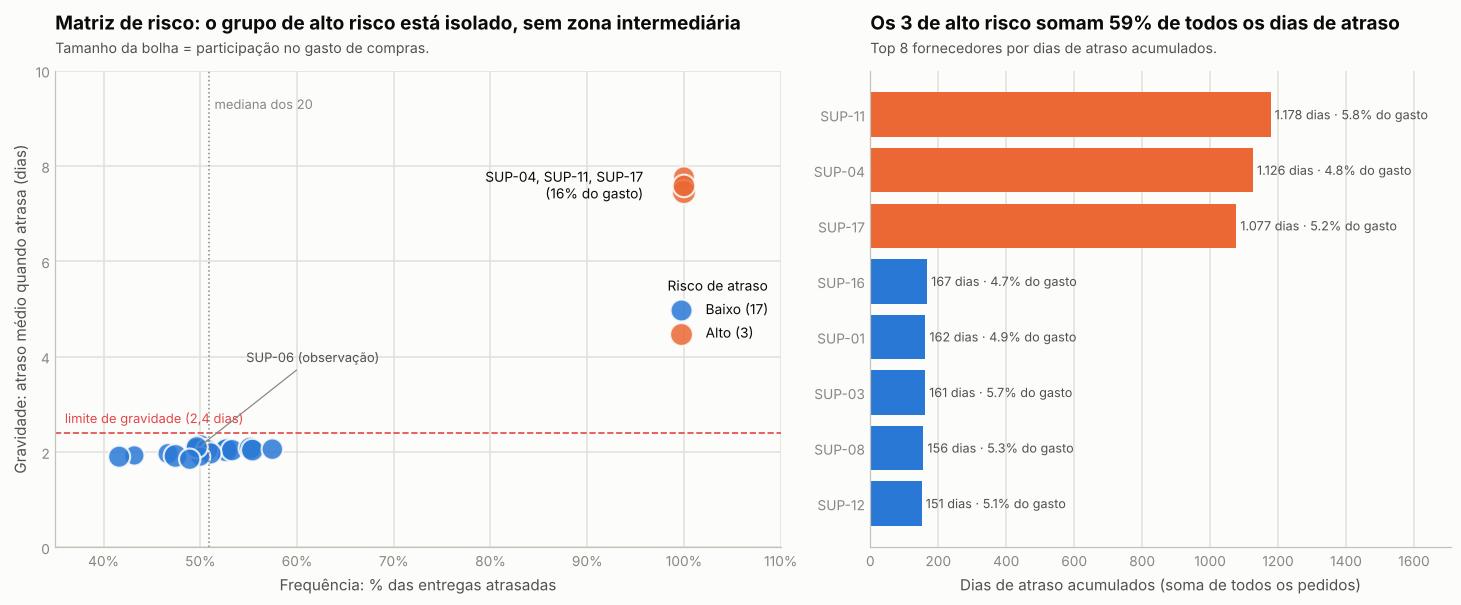

In [29]:
RISK_COR = {'Alto': ORANGE, 'Intermediário': '#e8b923', 'Baixo': BLUE}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={'width_ratios': [1.25, 1]})
for niv in ['Baixo', 'Intermediário', 'Alto']:
    s = r[r.risco == niv]
    if len(s): ax1.scatter(s.pct_atrasado * 100, s.severidade, s=s.share_gasto * 4200, c=RISK_COR[niv], alpha=.85, edgecolor=SURFACE, lw=1.4, label=f'{niv} ({len(s)})')
ax1.axhline(K['sev_limite'], color=RED, lw=1.1, ls='--'); ax1.text(36, K['sev_limite'] + .2, f"limite de gravidade ({num(K['sev_limite'],1)} dias)", color=RED, fontsize=8.5)
ax1.axvline(K['risco_base_mediana'] * 100, color=MUTED, lw=1, ls=':'); ax1.text(K['risco_base_mediana'] * 100 + .6, 9.2, 'mediana dos 20', color=MUTED, fontsize=8.5)
ax1.annotate(f"{', '.join(sorted(r[r.risco == 'Alto'].fornecedor))}\n({pct(r[r.risco == 'Alto'].share_gasto.sum(),0)} do gasto)", (r[r.risco == 'Alto'].pct_atrasado.mean() * 100 - 2, r[r.risco == 'Alto'].severidade.mean()), xytext=(-14, 0), textcoords='offset points', ha='right', va='center', fontsize=9, color=INK)
for rr in r[r.fornecedor.isin(K['obs'][:1])].itertuples(): ax1.annotate(f"{rr.fornecedor} (observação)", (rr.pct_atrasado * 100, rr.severidade), xytext=(30, 55), textcoords='offset points', fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle='-', color=MUTED, lw=.8))
ax1.set_xlim(35, 110); ax1.set_ylim(0, 10); estilo(ax1, 'both'); ax1.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax1.legend(loc='center right', fontsize=9, title='Risco de atraso', title_fontsize=9)
ax1.set_xlabel('Frequência: % das entregas atrasadas'); ax1.set_ylabel('Gravidade: atraso médio quando atrasa (dias)')
titulo(ax1, 'Matriz de risco: o grupo de alto risco está isolado, sem zona intermediária', 'Tamanho da bolha = participação no gasto de compras.')
# exposição: onde o risco e o dinheiro se encontram
ex = r.sort_values('dias_atraso_total', ascending=True).tail(8)
ax2.barh(ex.fornecedor, ex.dias_atraso_total, color=[RISK_COR[x] for x in ex.risco]); estilo(ax2, 'x'); ax2.set_xlabel('Dias de atraso acumulados (soma de todos os pedidos)')
for i, (v, gs) in enumerate(zip(ex.dias_atraso_total, ex.share_gasto)): ax2.text(v + 12, i, f'{v:,.0f} dias · {gs:.1%} do gasto'.replace(',', '.'), va='center', fontsize=8.3, color=INK2)
ax2.set_xlim(0, ex.dias_atraso_total.max() * 1.45)
titulo(ax2, f"Os 3 de alto risco somam {pct(K['cron_share_dias'],0)} de todos os dias de atraso", 'Top 8 fornecedores por dias de atraso acumulados.')
plt.tight_layout(); salvar(fig, 'a9_matriz_risco'); plt.show()

## Capítulo 8 · Dá para prever um atraso antes de ele acontecer?

Testamos modelos de previsão (programas que aprendem com o passado) para responder duas perguntas práticas: **(1)** dá para antecipar *quais pedidos* vão atrasar muito? **(2)** o que, de fato, carrega a informação?

**Como saber se um modelo é bom?** Comparamos com uma **linha de base ingênua** ("nenhum pedido vai atrasar muito"). E testamos de um jeito honesto: o modelo aprende com 2024 e é avaliado em 2025, como se estivesse prevendo o futuro.

**O que prever:** atraso grave (4 dias ou mais) e atraso de qualquer tamanho.
**Duas listas de informações:** **(A)** só do pedido (valor, itens, urgência, mês...) e **(B)** pedido + cadastro do fornecedor (país, tier, nota de qualidade...). Nunca entram dados que só se conhecem *depois* da entrega: isso seria "colar na prova" (vazamento de dados).

<details><summary>🔧 Nota técnica: modelos e validações</summary>

**Modelos:** regressão logística (soma ponderada de fatores que vira probabilidade), árvore de decisão com profundidade 3 (perguntas sim/não), Random Forest (muitas árvores votando) e Gradient Boosting (árvores pequenas corrigindo os erros umas das outras). **Validações:** (1) temporal: treina em 2024, testa em 2025; (2) aleatória 5-fold estratificada, que mistura períodos e pode superestimar o resultado; (3) leave-one-supplier-out: testa em fornecedor que o modelo nunca viu.
</details>

In [30]:
em = matriz_modelo(ped)
K['n_treino'] = int((em.ano == 2024).sum()); K['n_teste'] = int((em.ano == 2025).sum())
K['base_grave_treino'] = float(em[em.ano == 2024].grave.mean()); K['base_grave_teste'] = float(em[em.ano == 2025].grave.mean())
res_g, guarda_g = avaliar_classificacao(em, 'grave')
res_a, guarda_a = avaliar_classificacao(em, 'atrasado')
res_g.insert(0, 'alvo', 'grave (≥ 4 dias)'); res_a.insert(0, 'alvo', 'atrasado (> 0)')
res_clf = pd.concat([res_g, res_a], ignore_index=True)
res_clf.to_csv(f'{RES_DIR}/modelos_classificacao.csv', index=False)
fmt = {'precisão': '{:.2f}', 'recall': '{:.2f}', 'F1': '{:.2f}', 'ROC-AUC': '{:.3f}'}
display(Markdown('#### Alvo: atraso grave (≥ 4 dias), validação temporal 2024 → 2025'))
display(res_g[res_g.validação.str.startswith('Temporal')].drop(columns='validação').style.hide(axis='index').format(fmt))

#### Alvo: atraso grave (≥ 4 dias), validação temporal 2024 → 2025

alvo,atributos,modelo,precisão,recall,F1,ROC-AUC
grave (≥ 4 dias),Só atributos do pedido,Linha de base (classe majoritária),0.00,0.00,0.00,0.500
grave (≥ 4 dias),Só atributos do pedido,Regressão logística,0.00,0.00,0.00,0.504
grave (≥ 4 dias),Só atributos do pedido,Árvore de decisão (prof. 3),0.07,0.01,0.01,0.496
grave (≥ 4 dias),Só atributos do pedido,Random Forest,0.00,0.00,0.00,0.469
grave (≥ 4 dias),Só atributos do pedido,Gradient Boosting,0.32,0.03,0.05,0.488
grave (≥ 4 dias),Pedido + atributos do fornecedor,Linha de base (classe majoritária),0.00,0.00,0.00,0.500
grave (≥ 4 dias),Pedido + atributos do fornecedor,Regressão logística,0.90,1.00,0.95,0.991
grave (≥ 4 dias),Pedido + atributos do fornecedor,Árvore de decisão (prof. 3),0.91,0.65,0.76,0.970
grave (≥ 4 dias),Pedido + atributos do fornecedor,Random Forest,0.90,1.00,0.95,0.994
grave (≥ 4 dias),Pedido + atributos do fornecedor,Gradient Boosting,0.90,0.98,0.94,0.993


In [31]:
display(Markdown('#### Alvo: atraso grave: comparação entre as três validações (conjunto B: pedido + fornecedor)'))
v = res_g[res_g.atributos == 'Pedido + atributos do fornecedor'].pivot_table(index='modelo', columns='validação', values='F1')
display(v.style.format('{:.2f}', na_rep='—').background_gradient(cmap='Blues', vmin=0, vmax=1))
display(Markdown('#### Alvo: atraso grave: só atributos do pedido (conjunto A), validação temporal'))
display(res_g[(res_g.atributos == 'Só atributos do pedido') & res_g.validação.str.startswith('Temporal')].drop(columns=['validação', 'atributos']).style.hide(axis='index').format(fmt))
display(Markdown('#### Alvo: qualquer atraso, validação temporal (conjunto A e B)'))
display(res_a[res_a.validação.str.startswith('Temporal')].drop(columns='validação').style.hide(axis='index').format(fmt))

#### Alvo: atraso grave: comparação entre as três validações (conjunto B: pedido + fornecedor)

validação,Aleatória (5-fold),Fornecedor novo (leave-one-supplier-out),Temporal (2024→2025)
modelo,,,
Gradient Boosting,0.95,0.00,0.94
Linha de base (classe majoritária),0.00,0.00,0.00
Random Forest,0.95,0.00,0.95
Regressão logística,0.95,0.00,0.95
Árvore de decisão (prof. 3),0.73,0.00,0.76


#### Alvo: atraso grave: só atributos do pedido (conjunto A), validação temporal

alvo,modelo,precisão,recall,F1,ROC-AUC
grave (≥ 4 dias),Linha de base (classe majoritária),0.00,0.00,0.00,0.500
grave (≥ 4 dias),Regressão logística,0.00,0.00,0.00,0.504
grave (≥ 4 dias),Árvore de decisão (prof. 3),0.07,0.01,0.01,0.496
grave (≥ 4 dias),Random Forest,0.00,0.00,0.00,0.469
grave (≥ 4 dias),Gradient Boosting,0.32,0.03,0.05,0.488


#### Alvo: qualquer atraso, validação temporal (conjunto A e B)

alvo,atributos,modelo,precisão,recall,F1,ROC-AUC
atrasado (> 0),Só atributos do pedido,Linha de base (classe majoritária),0.59,1.00,0.74,0.500
atrasado (> 0),Só atributos do pedido,Regressão logística,0.59,1.00,0.74,0.508
atrasado (> 0),Só atributos do pedido,Árvore de decisão (prof. 3),0.59,0.99,0.74,0.513
atrasado (> 0),Só atributos do pedido,Random Forest,0.59,0.95,0.73,0.515
atrasado (> 0),Só atributos do pedido,Gradient Boosting,0.60,0.82,0.69,0.533
atrasado (> 0),Pedido + atributos do fornecedor,Linha de base (classe majoritária),0.59,1.00,0.74,0.500
atrasado (> 0),Pedido + atributos do fornecedor,Regressão logística,0.62,0.67,0.64,0.627
atrasado (> 0),Pedido + atributos do fornecedor,Árvore de decisão (prof. 3),0.76,0.41,0.54,0.636
atrasado (> 0),Pedido + atributos do fornecedor,Random Forest,0.63,0.65,0.64,0.629
atrasado (> 0),Pedido + atributos do fornecedor,Gradient Boosting,0.64,0.64,0.64,0.627


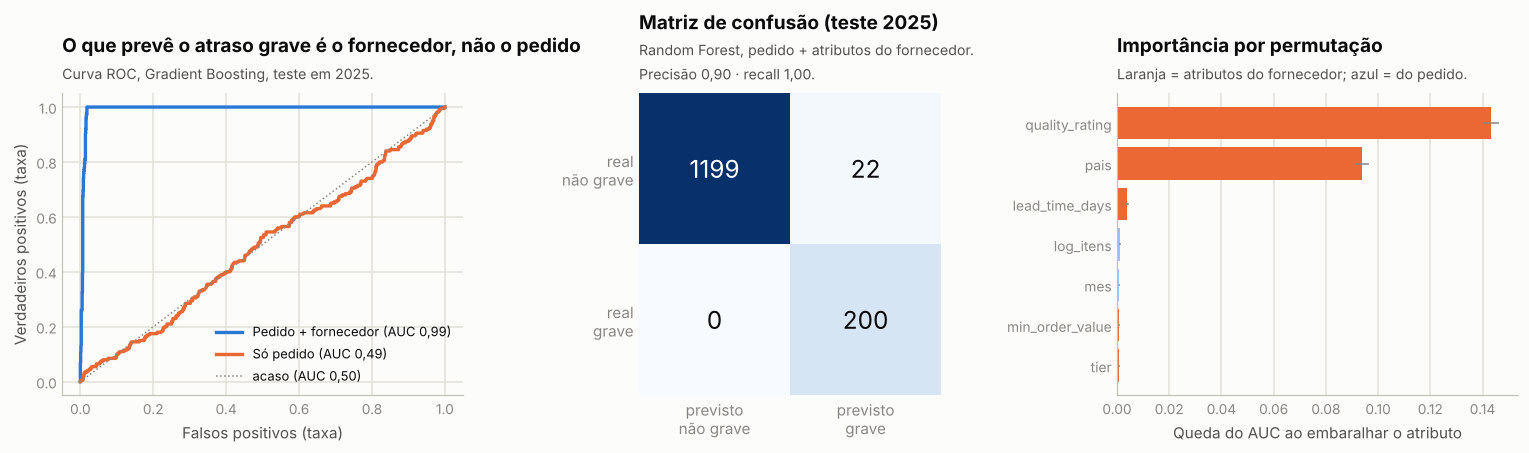

In [32]:
# --- Regra simples (sem ML) como referência, matriz de confusão e curva ROC do melhor modelo ---
from sklearn.metrics import roc_curve, confusion_matrix
rs = regra_simples(em, 'grave'); K['regra'] = {k_: (v if isinstance(v, list) else float(v)) for k_, v in rs.items()}
tmp = res_g[(res_g.validação.str.startswith('Temporal')) & (res_g.modelo != 'Linha de base (classe majoritária)')]
mb = tmp.sort_values(['F1', 'ROC-AUC'], ascending=False).iloc[0]
K['melhor'] = dict(modelo=mb.modelo, atributos=mb.atributos, f1=float(mb.F1), auc=float(mb['ROC-AUC']), prec=float(mb['precisão']), rec=float(mb.recall))
yt, pr = guarda_g[(mb.atributos, mb.modelo)]
cm = confusion_matrix(yt, (pr >= .5).astype(int)); K['cm'] = cm.tolist()
yA, pA = guarda_g[('Só atributos do pedido', 'Gradient Boosting')]; yB, pB = guarda_g[('Pedido + atributos do fornecedor', 'Gradient Boosting')]
fa, ta, _ = roc_curve(yA, pA); fb, tb, _ = roc_curve(yB, pB)
from sklearn.metrics import roc_auc_score
K['auc_A_gb'] = float(roc_auc_score(yA, pA)); K['auc_B_gb'] = float(roc_auc_score(yB, pB))
# alvo 'atrasado' no conjunto A
yAt, pAt = guarda_a[('Só atributos do pedido', 'Gradient Boosting')]; K['auc_atrasado_A'] = float(roc_auc_score(yAt, pAt))
yBt, pBt = guarda_a[('Pedido + atributos do fornecedor', 'Gradient Boosting')]; K['auc_atrasado_B'] = float(roc_auc_score(yBt, pBt))
K['lr_B_auc'] = float(res_g[(res_g.modelo == 'Regressão logística') & (res_g.atributos == 'Pedido + atributos do fornecedor') & res_g.validação.str.startswith('Temporal')]['ROC-AUC'].iloc[0])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.2))
ax1.plot(fb, tb, color=BLUE, lw=2.2, label=f"Pedido + fornecedor (AUC {num(K['auc_B_gb'],2)})"); ax1.plot(fa, ta, color=ORANGE, lw=2.2, label=f"Só pedido (AUC {num(K['auc_A_gb'],2)})")
ax1.plot([0, 1], [0, 1], color=MUTED, lw=1, ls=':', label='acaso (AUC 0,50)'); estilo(ax1, 'both'); ax1.legend(fontsize=8.5, loc='lower right')
ax1.set_xlabel('Falsos positivos (taxa)'); ax1.set_ylabel('Verdadeiros positivos (taxa)'); titulo(ax1, 'O que prevê o atraso grave é o fornecedor, não o pedido', 'Curva ROC, Gradient Boosting, teste em 2025.')
ax2.imshow(cm, cmap='Blues'); ax2.set_xticks([0, 1]); ax2.set_yticks([0, 1]); ax2.set_xticklabels(['previsto\nnão grave', 'previsto\ngrave']); ax2.set_yticklabels(['real\nnão grave', 'real\ngrave'])
for (i, j), val in np.ndenumerate(cm): ax2.text(j, i, f'{val}', ha='center', va='center', fontsize=16, color='white' if val > cm.max() / 2 else INK)
ax2.grid(False); [ax2.spines[s].set_visible(False) for s in ax2.spines]; ax2.tick_params(length=0)
titulo(ax2, 'Matriz de confusão (teste 2025)', f"{K['melhor']['modelo']}, {K['melhor']['atributos'].lower()}.\nPrecisão {num(K['melhor']['prec'],2)} · recall {num(K['melhor']['rec'],2)}.")
imp = importancia_permutacao(em, 'grave').head(7).sort_values('queda_AUC')
ax3.barh(imp.atributo, imp.queda_AUC, xerr=imp.dp, color=[ORANGE if a_ in NUM_FORN + CAT_FORN else '#9cc3f0' for a_ in imp.atributo], error_kw=dict(ecolor=MUTED, lw=1)); estilo(ax3, 'x')
ax3.set_xlabel('Queda do AUC ao embaralhar o atributo'); titulo(ax3, 'Importância por permutação', 'Laranja = atributos do fornecedor; azul = do pedido.')
K['imp_top'] = imp.sort_values('queda_AUC', ascending=False).atributo.head(3).tolist()
plt.tight_layout(); salvar(fig, 'a10_modelos_roc_confusao'); plt.show()

In [33]:
# --- Regressão: prever os DIAS de atraso ---
res_r = avaliar_regressao(em); res_r.to_csv(f'{RES_DIR}/modelos_regressao.csv', index=False)
display(Markdown('#### Regressão do atraso em dias (MAE e RMSE em dias; R² = parcela da variação explicada)'))
display(res_r.style.hide(axis='index').format({'MAE': '{:.2f}', 'RMSE': '{:.2f}', 'R²': '{:.3f}'}).background_gradient(subset=['R²'], cmap='Blues', vmin=0, vmax=1))
rr_t = res_r[res_r.validação.str.startswith('Temporal')]
K['reg_base_mae'] = float(rr_t[rr_t.modelo.str.startswith('Linha')].MAE.iloc[0])
K['reg_A_r2'] = float(rr_t[(rr_t.atributos == 'Só atributos do pedido') & (rr_t.modelo == 'Gradient Boosting')]['R²'].iloc[0])
K['reg_B_r2'] = float(rr_t[(rr_t.atributos != 'Só atributos do pedido') & (rr_t.modelo == 'Gradient Boosting')]['R²'].iloc[0])
K['reg_B_mae'] = float(rr_t[(rr_t.atributos != 'Só atributos do pedido') & (rr_t.modelo == 'Gradient Boosting')].MAE.iloc[0])
rr_l = res_r[res_r.validação.str.startswith('Fornecedor')]
K['reg_logo_r2_max'] = float(rr_l[~rr_l.modelo.str.startswith('Linha')]['R²'].max())

#### Regressão do atraso em dias (MAE e RMSE em dias; R² = parcela da variação explicada)

atributos,modelo,validação,MAE,RMSE,R²
Só atributos do pedido,Linha de base (média do treino),Temporal (2024→2025),2.34,3.16,-0.001
Só atributos do pedido,Linha de base (média do treino),Fornecedor novo (leave-one-supplier-out),2.45,3.37,-0.072
Só atributos do pedido,Regressão linear,Temporal (2024→2025),2.34,3.16,-0.003
Só atributos do pedido,Regressão linear,Fornecedor novo (leave-one-supplier-out),2.45,3.37,-0.073
Só atributos do pedido,Random Forest,Temporal (2024→2025),2.37,3.20,-0.024
Só atributos do pedido,Random Forest,Fornecedor novo (leave-one-supplier-out),2.47,3.39,-0.082
Só atributos do pedido,Gradient Boosting,Temporal (2024→2025),2.44,3.27,-0.071
Só atributos do pedido,Gradient Boosting,Fornecedor novo (leave-one-supplier-out),2.50,3.42,-0.103
Pedido + atributos do fornecedor,Linha de base (média do treino),Temporal (2024→2025),2.34,3.16,-0.001
Pedido + atributos do fornecedor,Linha de base (média do treino),Fornecedor novo (leave-one-supplier-out),2.45,3.37,-0.072


In [34]:
lA = res_g[(res_g.atributos == 'Só atributos do pedido') & res_g.validação.str.startswith('Temporal') & ~res_g.modelo.str.startswith('Linha')]
lo_ = res_g[res_g.validação.str.startswith('Fornecedor') & ~res_g.modelo.str.startswith('Linha')]
rb = K['regra']
display(Markdown(f"""
**Em uma frase:** os modelos só "acertam" quando conhecem o fornecedor. Com as informações do pedido, não preveem nada: o que importa é *quem entrega*.

1. ✅ **Fato:** treinamos com {num(K['n_treino'])} pedidos de 2024 e testamos em {num(K['n_teste'])} de 2025. A taxa de atraso grave é parecida nos dois períodos ({pct(K['base_grave_treino'],1)} e {pct(K['base_grave_teste'],1)}). A linha de base acerta ~{pct(1-K['base_grave_teste'],0)} das vezes, mas **não detecta nenhum** atraso grave; por isso olhamos precisão, recall e F1, e não só a "taxa de acerto".
2. 🔗 **Com o cadastro do fornecedor o desempenho é altíssimo** (melhor modelo: *{K['melhor']['modelo']}*, F1 = {num(K['melhor']['f1'],2)}, AUC = {num(K['melhor']['auc'],2)}). **Mas isso não é "previsão inteligente".** País, tier e nota de qualidade funcionam como um "crachá" que identifica o fornecedor; como o atraso grave é característica de 3 fornecedores, basta o modelo reconhecê-los.
3. ✅ **Fato:** **só com informações do pedido, o modelo não prevê:** AUC de {num(K['auc_A_gb'],2)} (0,50 = acaso) e F1 máximo de {num(lA.F1.max(),2)}. Valor, tamanho, urgência, mês e dia da semana não anunciam o atraso grave.
4. ✅ **Fato:** prever **qualquer atraso** também não funciona bem (AUC de {num(K['auc_atrasado_A'],2)} só com o pedido e {num(K['auc_atrasado_B'],2)} com o fornecedor). O atraso curto é, na prática, aleatório entre os fornecedores normais.
5. ✅ **Fato:** em um **fornecedor novo** (que o modelo nunca viu), o melhor F1 cai para **{num(lo_.F1.max(),2)}**: o modelo não generaliza, só reconhece os conhecidos.
6. **Uma regra simples faz o mesmo:** marcar os pedidos dos fornecedores com atraso médio atípico em 2024 ({', '.join(rb['fornecedores_marcados'])}) dá precisão {num(rb['precisão'],2)}, recall {num(rb['recall'],2)} e F1 {num(rb['F1'],2)} em 2025, no mesmo nível dos melhores modelos (F1 {num(K['melhor']['f1'],2)}), sem "caixa-preta".
7. **Previsão dos dias de atraso:** erro médio de {num(K['reg_B_mae'],2)} dia com o cadastro do fornecedor, contra {num(K['reg_base_mae'],2)} da linha de base. O R² (parcela da variação explicada) é de {num(K['reg_A_r2'],2)} só com o pedido (negativo = pior que prever a média) e {num(K['reg_B_r2'],2)} com o fornecedor.

**Conclusão:** o valor dos modelos aqui é **explicar**, não prever. Eles confirmam que a variável que importa é o fornecedor. Para operar, o melhor é uma **regra simples de monitoramento por fornecedor** (capítulo 7), e não um modelo pedido a pedido.

<details><summary>🔧 Nota técnica: glossário das métricas</summary>

- **Precisão:** dos pedidos que o modelo apontou como graves, quantos eram mesmo graves.
- **Recall:** dos pedidos realmente graves, quantos o modelo encontrou.
- **F1:** média entre precisão e recall (0 a 1).
- **ROC-AUC:** capacidade de colocar os graves acima dos não graves (0,5 = acaso; 1 = perfeito).
- **MAE / RMSE / R²:** erro médio em dias; erro que pesa mais os grandes; parcela da variação explicada.
- O AUC agrupado no esquema "fornecedor novo" foi omitido de propósito (misturaria 20 modelos diferentes).
- Em fornecedor novo, o R² da previsão de dias chega no máximo a {num(K['reg_logo_r2_max'],2)}.
</details>
"""))


**Em uma frase:** os modelos só "acertam" quando conhecem o fornecedor. Com as informações do pedido, não preveem nada: o que importa é *quem entrega*.

1. ✅ **Fato:** treinamos com 1.386 pedidos de 2024 e testamos em 1.421 de 2025. A taxa de atraso grave é parecida nos dois períodos (14,6% e 14,1%). A linha de base acerta ~86% das vezes, mas **não detecta nenhum** atraso grave; por isso olhamos precisão, recall e F1, e não só a "taxa de acerto".
2. 🔗 **Com o cadastro do fornecedor o desempenho é altíssimo** (melhor modelo: *Random Forest*, F1 = 0,95, AUC = 0,99). **Mas isso não é "previsão inteligente".** País, tier e nota de qualidade funcionam como um "crachá" que identifica o fornecedor; como o atraso grave é característica de 3 fornecedores, basta o modelo reconhecê-los.
3. ✅ **Fato:** **só com informações do pedido, o modelo não prevê:** AUC de 0,49 (0,50 = acaso) e F1 máximo de 0,05. Valor, tamanho, urgência, mês e dia da semana não anunciam o atraso grave.
4. ✅ **Fato:** prever **qualquer atraso** também não funciona bem (AUC de 0,53 só com o pedido e 0,63 com o fornecedor). O atraso curto é, na prática, aleatório entre os fornecedores normais.
5. ✅ **Fato:** em um **fornecedor novo** (que o modelo nunca viu), o melhor F1 cai para **0,00**: o modelo não generaliza, só reconhece os conhecidos.
6. **Uma regra simples faz o mesmo:** marcar os pedidos dos fornecedores com atraso médio atípico em 2024 (SUP-04, SUP-11, SUP-17) dá precisão 0,90, recall 1,00 e F1 0,95 em 2025, no mesmo nível dos melhores modelos (F1 0,95), sem "caixa-preta".
7. **Previsão dos dias de atraso:** erro médio de 1,65 dia com o cadastro do fornecedor, contra 2,34 da linha de base. O R² (parcela da variação explicada) é de -0,07 só com o pedido (negativo = pior que prever a média) e 0,60 com o fornecedor.

**Conclusão:** o valor dos modelos aqui é **explicar**, não prever. Eles confirmam que a variável que importa é o fornecedor. Para operar, o melhor é uma **regra simples de monitoramento por fornecedor** (capítulo 7), e não um modelo pedido a pedido.

<details><summary>🔧 Nota técnica: glossário das métricas</summary>

- **Precisão:** dos pedidos que o modelo apontou como graves, quantos eram mesmo graves.
- **Recall:** dos pedidos realmente graves, quantos o modelo encontrou.
- **F1:** média entre precisão e recall (0 a 1).
- **ROC-AUC:** capacidade de colocar os graves acima dos não graves (0,5 = acaso; 1 = perfeito).
- **MAE / RMSE / R²:** erro médio em dias; erro que pesa mais os grandes; parcela da variação explicada.
- O AUC agrupado no esquema "fornecedor novo" foi omitido de propósito (misturaria 20 modelos diferentes).
- Em fornecedor novo, o R² da previsão de dias chega no máximo a -0,05.
</details>


## Capítulo 9 · Conferência, recomendações e conclusão

### 9.1 Os números batem entre si?
Antes de concluir, conferimos se tabelas, indicadores e modelos contam a mesma história e se as premissas dos testes foram respeitadas.

In [35]:
chk = []
def ok(nome, cond, det=''): chk.append({'verificação': nome, 'resultado': '✅ OK' if cond else '❌ FALHOU', 'detalhe': det}); return cond
ok('Pedidos: base original = base tratada = tabela de pedidos', len(brutos['purchase_order']) == len(T['purchase_order']) == len(ped) == 3000, f"{len(ped)}")
ok('Entregues + cancelados = total', len(ent) + int((~ped.entregue).sum()) == len(ped), f"{len(ent)} + {int((~ped.entregue).sum())}")
ok('Classes antecipada + pontual + atrasada = 100%', abs(K['pct_ant'] + K['pct_pont'] + K['pct_atr'] - 1) < 1e-9, f"{num(K['pct_ant']+K['pct_pont']+K['pct_atr'],6)}")
ok('% atrasado ponderado dos fornecedores = % atrasado geral', abs((f.pct_atrasado * f.pedidos).sum() / f.pedidos.sum() - K['pct_atr']) < 1e-9)
ok('Soma dos pedidos por fornecedor = entregues', int(f.pedidos.sum()) == len(ent))
ok('Soma da participação nos dias de atraso = 100%', abs(f.share_dias_atraso.sum() - 1) < 1e-9)
ok('Média do atraso (fornecedores ponderados) = média geral', abs((f.atraso_medio * f.pedidos).sum() / f.pedidos.sum() - ent.atraso.mean()) < 1e-9)
ok('Atraso calculado = entrega real − prometido (recálculo independente)', (((T['purchase_order'].set_index('po_id').actual_delivery_date - T['purchase_order'].set_index('po_id').promised_date).dt.days.reindex(ent.po_id).values) == ent.atraso.values).all())
ok('Atraso grave só ocorre em fornecedores classificados como alto risco', set(ent[ent.grave == 1].fornecedor) <= set(r[r.risco == 'Alto'].fornecedor))
ok('Crônicos (z modificado) = Alto risco = Grupo 1 do K-Means', set(K['cron_nomes']) == set(r[r.risco == 'Alto'].fornecedor) and K['k_igual_risco'])
ok('Conclusão robusta a retirar outliers', K['robusto_cronicos'])
ok('Sem vazamento: atributos do modelo não incluem variáveis pós-entrega', not (set(NUM_PED + NUM_FORN + CAT_FORN) & {'atraso', 'atrasado', 'grave', 'classe', 'qtd_rec', 'qtd_rej', 'gasto', 'entregue', 'atraso_rel'}))
ok('Treino (2024) e teste (2025) não se sobrepõem', set(em[em.ano == 2024].po_id).isdisjoint(set(em[em.ano == 2025].po_id)))
# premissas estatísticas
shp = stats.shapiro(ent.atraso.sample(2000, random_state=SEED)); res_ols = smf.ols('atraso ~ ' + form, data=ent_nc).fit()
bp_ = sm.stats.diagnostic.het_breuschpagan(res_ols.resid, res_ols.model.exog)
K['shapiro_p'] = float(shp.pvalue); K['bp_p'] = float(bp_[1]); K['n_checks_ok'] = sum(c_['resultado'].startswith('✅') for c_ in chk); K['n_checks'] = len(chk)
display(pd.DataFrame(chk).style.hide(axis='index').set_properties(**{'text-align': 'left'}))
display(Markdown(f"""
**Conferência concluída:** **{K['n_checks_ok']} de {K['n_checks']}** verificações passaram (tabela acima).

<details><summary>🔧 Nota técnica: premissas estatísticas</summary>

O atraso **não é normal** (Shapiro–Wilk, p = {K['shapiro_p']:.1e}; é um número inteiro e assimétrico), por isso usamos testes **não paramétricos** (Kruskal–Wallis, Mann–Whitney, Spearman, Kendall, Fisher). Na regressão linear, a heterocedasticidade (Breusch–Pagan, p = {num(K['bp_p'],2)}) é tratada com erros robustos HC3, e a leitura é descritiva (R² ≈ 0). **Múltiplos testes:** fizemos muitos testes; resultados isolados com p entre 0,01 e 0,05 não são tratados como achados, só os efeitos grandes e consistentes (3 fornecedores).
</details>
"""))

verificação,resultado,detalhe
Pedidos: base original = base tratada = tabela de pedidos,✅ OK,3000
Entregues + cancelados = total,✅ OK,2807 + 193
Classes antecipada + pontual + atrasada = 100%,✅ OK,"1,000000"
% atrasado ponderado dos fornecedores = % atrasado geral,✅ OK,
Soma dos pedidos por fornecedor = entregues,✅ OK,
Soma da participação nos dias de atraso = 100%,✅ OK,
Média do atraso (fornecedores ponderados) = média geral,✅ OK,
Atraso calculado = entrega real − prometido (recálculo independente),✅ OK,
Atraso grave só ocorre em fornecedores classificados como alto risco,✅ OK,
Crônicos (z modificado) = Alto risco = Grupo 1 do K-Means,✅ OK,



**Conferência concluída:** **13 de 13** verificações passaram (tabela acima).

<details><summary>🔧 Nota técnica: premissas estatísticas</summary>

O atraso **não é normal** (Shapiro–Wilk, p = 1.5e-40; é um número inteiro e assimétrico), por isso usamos testes **não paramétricos** (Kruskal–Wallis, Mann–Whitney, Spearman, Kendall, Fisher). Na regressão linear, a heterocedasticidade (Breusch–Pagan, p = 0,18) é tratada com erros robustos HC3, e a leitura é descritiva (R² ≈ 0). **Múltiplos testes:** fizemos muitos testes; resultados isolados com p entre 0,01 e 0,05 não são tratados como achados, só os efeitos grandes e consistentes (3 fornecedores).
</details>


### 9.2 Principais descobertas (fato · associação · hipótese)

In [36]:
ins = pd.DataFrame([
    ('✅ FATO', 'Dimensão', f"{pct(K['pct_atr'],0)} das entregas atrasam, mas o atraso típico é curto (mediana {num(K['atraso_mediano'],0)} dia). {pct(K['pct_grave'],1)} ({num(K['n_grave'])}) passam de 3 dias, até {K['atraso_max']}.", 'Hist. + KPIs (Cap. 1)'),
    ('FATO', 'Concentração', f"{', '.join(K['cron_nomes'])} atrasam em 100% das entregas, ~{num(np.mean(K['cron_sev']),1)} dias; {pct(K['cron_share_dias'],0)} dos dias de atraso e {pct(K['grave_share_cron'],0)} dos atrasos graves, com {pct(K['cron_share_gasto'],0)} do gasto.", 'Ranking + matriz de risco (Cap. 2, 7)'),
    ('FATO', 'Outros 17', f"Perfil quase idêntico: {pct(K['nao_pct_min'],0)}–{pct(K['nao_pct_max'],0)} atrasados, por {num(K['nao_sev_min'],1)}–{num(K['nao_sev_max'],1)} dias; nenhum atraso grave.", 'Ranking (Cap. 2)'),
    ('FATO', 'Persistência', f"Sem tendência (p = {num(K['tau_tot'][1],2)}) nem sazonalidade (p = {num(K['p_sazon'],2)}) em 24 meses: o problema é estrutural.", 'Série temporal (Cap. 3)'),
    ('ASSOCIAÇÃO', 'Fatores', f"País/tier parecem associados, mas o efeito desaparece sem os 3 crônicos. Atributos do pedido não explicam o atraso (R² = {num(K['ols_r2'],3)}); o fornecedor explica {pct(K['r2_forn'],0)}.", 'Cap. 3, 4, 8'),
    ('FATO', 'Custo / volume / qualidade', f"Sem prêmio de preço (índice {num(K['idx_custo_min'],2)}–{num(K['idx_custo_max'],2)}), volume igual, rejeição igual ({pct(K['rej_cron'],1)} vs {pct(K['rej_nao'],1)}), sem mais pedidos urgentes.", 'Cap. 5.1–5.2'),
    ('ASSOCIAÇÃO (nula)', 'Estoque e serviço', f"Sem associação detectável com ruptura (p = {num(K['painel']['ruptura'][1],2)}) nem com nível de serviço (p = {num(K['rho_servico'][1],2)}); a base não permite atribuir causalidade.", 'Cap. 5.3'),
    ('HIPÓTESE', 'Exposição de estoque', f"O ROP cobre {num(K['cob_med'],0)} dias de demanda em mediana; atrasos de 10–14 dias podem superá-lo em {pct(K['cob_lt_max'],0)} dos pares. Risco potencial, não medido.", 'Cap. 5.3'),
    ('FATO', 'Modelos', f"O modelo de ML só acerta quando conhece o fornecedor (AUC {num(K['auc_B_gb'],2)} vs {num(K['auc_A_gb'],2)} só com pedido). Uma regra simples por fornecedor faz o mesmo (F1 {num(K['regra']['F1'],2)}).", 'Cap. 8'),
    ('FATO', 'Outliers', f"Os extremos de atraso são eventos reais ({pct(K['out_atraso_cron_share'],0)} dos 3 fornecedores); removê-los esconderia o problema e a lista de crônicos não muda.", 'Cap. 6'),
], columns=['natureza', 'tema', 'achado', 'onde'])
display(ins.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'normal'}))

natureza,tema,achado,onde
✅ FATO,Dimensão,"58% das entregas atrasam, mas o atraso típico é curto (mediana 1 dia). 14,4% (403) passam de 3 dias, até 14.",Hist. + KPIs (Cap. 1)
FATO,Concentração,"SUP-04, SUP-17, SUP-11 atrasam em 100% das entregas, ~7,6 dias; 59% dos dias de atraso e 100% dos atrasos graves, com 16% do gasto.","Ranking + matriz de risco (Cap. 2, 7)"
FATO,Outros 17,"Perfil quase idêntico: 42%–57% atrasados, por 1,9–2,1 dias; nenhum atraso grave.",Ranking (Cap. 2)
FATO,Persistência,"Sem tendência (p = 0,62) nem sazonalidade (p = 0,68) em 24 meses: o problema é estrutural.",Série temporal (Cap. 3)
ASSOCIAÇÃO,Fatores,"País/tier parecem associados, mas o efeito desaparece sem os 3 crônicos. Atributos do pedido não explicam o atraso (R² = 0,004); o fornecedor explica 63%.","Cap. 3, 4, 8"
FATO,Custo / volume / qualidade,"Sem prêmio de preço (índice 0,99–1,01), volume igual, rejeição igual (2,4% vs 2,4%), sem mais pedidos urgentes.",Cap. 5.1–5.2
ASSOCIAÇÃO (nula),Estoque e serviço,"Sem associação detectável com ruptura (p = 0,29) nem com nível de serviço (p = 0,62); a base não permite atribuir causalidade.",Cap. 5.3
HIPÓTESE,Exposição de estoque,"O ROP cobre 27 dias de demanda em mediana; atrasos de 10–14 dias podem superá-lo em 13% dos pares. Risco potencial, não medido.",Cap. 5.3
FATO,Modelos,"O modelo de ML só acerta quando conhece o fornecedor (AUC 0,99 vs 0,49 só com pedido). Uma regra simples por fornecedor faz o mesmo (F1 0,95).",Cap. 8
FATO,Outliers,Os extremos de atraso são eventos reais (100% dos 3 fornecedores); removê-los esconderia o problema e a lista de crônicos não muda.,Cap. 6


In [37]:
c_prazo = f[f.cronico].assign(entrega_real=lambda d: d.prazo_prometido + d.atraso_medio).sort_values('atraso_rel', ascending=False)
pior = c_prazo.iloc[0]; maior_g = f[f.cronico].sort_values('gasto').iloc[-1]
display(Markdown(f"""
### 9.3 Recomendações (com base nos dados)

| # | Ação | Evidência que sustenta | Prioridade |
|---|---|---|---|
| 1 | **Plano de ação individual com os 3 fornecedores de alto risco** ({', '.join(K['cron_nomes'])}): metas de prazo, escalonamento, revisão contratual, auditoria de processo | 100% de entregas atrasadas, ~{num(float(np.mean(K['cron_sev'])),1)} dias, {pct(K['cron_share_dias'],0)} de todos os dias de atraso e {pct(K['grave_share_cron'],0)} dos atrasos graves | **Alta** |
| 2 | **Gestão por fornecedor, não por categoria** (país, tier e fonte única não são bons critérios de atuação) | Efeito de país/tier some sem os 3 crônicos; há crônico em tiers A, B e C | **Alta** |
| 3 | **Medir o custo do atraso**: registrar multas, frete urgente, parada de linha e ruptura por pedido e ligar pedidos de compra às remessas | Hoje não há dado para atribuir R$ ao atraso | **Alta** (habilita as demais) |
| 4 | **Revisar prazos prometidos dos crônicos** ou negociar prazo realista com penalidade: {pior.fornecedor} promete {num(pior.prazo_prometido,0)} dias e entrega em ~{num(pior.entrega_real,0)} (+{pct(pior.atraso_rel,0)}); {maior_g.fornecedor} (maior gasto entre eles) promete {num(maior_g.prazo_prometido,0)} e entrega em ~{num(maior_g.prazo_prometido + maior_g.atraso_medio,0)} | Atraso relativo ao prazo: {', '.join(f'{r_.fornecedor} {pct(r_.atraso_rel,0)}' for r_ in c_prazo.itertuples())} | Média |
| 5 | **Teste de proteção do ROP** nos produtos de maior exposição a esses fornecedores | Cobertura mediana de ~{num(K['cob_med'],0)} dias vs caudas de 10–14 dias (hipótese) | Média |
| 6 | **Monitoramento simples** (painel com % atrasado, severidade, z robusto) e alerta quando um fornecedor entrar na lista de observação ({', '.join(K['obs'])}) | Regra simples iguala o ML; modelo pedido a pedido não se justifica | Média |
| 7 | **Avaliar alternativas para os crônicos onde houver substituto** (nenhum é fonte única) | Os 3 crônicos são multi-fonte: há fornecedores alternativos no cadastro | Média/Baixa |
"""))


### 9.3 Recomendações (com base nos dados)

| # | Ação | Evidência que sustenta | Prioridade |
|---|---|---|---|
| 1 | **Plano de ação individual com os 3 fornecedores de alto risco** (SUP-04, SUP-17, SUP-11): metas de prazo, escalonamento, revisão contratual, auditoria de processo | 100% de entregas atrasadas, ~7,6 dias, 59% de todos os dias de atraso e 100% dos atrasos graves | **Alta** |
| 2 | **Gestão por fornecedor, não por categoria** (país, tier e fonte única não são bons critérios de atuação) | Efeito de país/tier some sem os 3 crônicos; há crônico em tiers A, B e C | **Alta** |
| 3 | **Medir o custo do atraso**: registrar multas, frete urgente, parada de linha e ruptura por pedido e ligar pedidos de compra às remessas | Hoje não há dado para atribuir R$ ao atraso | **Alta** (habilita as demais) |
| 4 | **Revisar prazos prometidos dos crônicos** ou negociar prazo realista com penalidade: SUP-17 promete 7 dias e entrega em ~15 (+108%); SUP-11 (maior gasto entre eles) promete 35 e entrega em ~42 | Atraso relativo ao prazo: SUP-17 108%, SUP-04 43%, SUP-11 21% | Média |
| 5 | **Teste de proteção do ROP** nos produtos de maior exposição a esses fornecedores | Cobertura mediana de ~27 dias vs caudas de 10–14 dias (hipótese) | Média |
| 6 | **Monitoramento simples** (painel com % atrasado, severidade, z robusto) e alerta quando um fornecedor entrar na lista de observação (SUP-06, SUP-18, SUP-10) | Regra simples iguala o ML; modelo pedido a pedido não se justifica | Média |
| 7 | **Avaliar alternativas para os crônicos onde houver substituto** (nenhum é fonte única) | Os 3 crônicos são multi-fonte: há fornecedores alternativos no cadastro | Média/Baixa |


### 9.4 Limitações

- **Dados sintéticos (2024–2025)**: padrões fortes e "limpos" (3 crônicos + 17 homogêneos) são improváveis em dados reais; as conclusões valem para esta base.
- **Sem custo financeiro do atraso** (multas, frete urgente, parada de linha, ruptura em R$): nenhum valor monetário é atribuído.
- **Sem ligação compra ↔ venda/remessa** e todos os produtos comprados dos mesmos 20 fornecedores: o desenho dificilmente detectaria impacto em estoque e serviço, mesmo que exista. *Ausência de evidência não é evidência de ausência.*
- **n = 20 fornecedores**: correlações em nível de fornecedor são frágeis; o ranking é robusto, mas a inferência estatística entre fornecedores é limitada.
- **Janela de 24 meses**: insuficiente para modelos de séries temporais (não aplicados de propósito).
- **Pedidos cancelados** (sem data de entrega) ficam fora das métricas de atraso; não foi feita imputação.
- **Modelos**: os atributos de cadastro do fornecedor *identificam* o fornecedor; os resultados com ele refletem memorização, não previsão (ver Cap. 8). Em fornecedor novo, não há generalização.
- **Definição de "grave" (≥ 4 dias)** vem de uma quebra na distribuição; é uma escolha analítica, e conclusões qualitativas não dependem dela.

In [38]:
display(Markdown(f"""
## Conclusão executiva

**1. Qual é a dimensão do problema dos atrasos?**
**{pct(K['pct_atr'],0)}** das {num(K['n_ent'])} entregas chegam depois do prometido, mas, em geral, por pouco (mediana de {num(K['atraso_mediano'],0)} dia; {pct(K['pct_ant'],0)} chegam antes). O problema relevante é a **cauda**: **{num(K['n_grave'])} entregas ({pct(K['pct_grave'],1)})** com 4 a {K['atraso_max']} dias de atraso. É **estável** em 24 meses, sem tendência nem sazonalidade.

**2. Quais fornecedores representam maior risco?**
**{', '.join(K['cron_nomes'])}** (alto risco): atrasam em 100% das entregas, em média **{num(min(K['cron_sev']),1)}–{num(max(K['cron_sev']),1)} dias**, somando **{pct(K['cron_share_dias'],0)} dos dias de atraso** e **{pct(K['grave_share_cron'],0)} dos atrasos graves**. Os outros 17 são de baixo risco e tão parecidos entre si que nenhum fica no meio. Lista de observação: {', '.join(K['obs'])}.

**3. Quais fatores estão associados aos atrasos?**
Apenas a **identidade do fornecedor** ({pct(K['r2_forn'],0)} da variação). Valor, itens, urgência, mês e dia da semana **não** explicam; país e tier só *parecem* explicar por causa dos 3 crônicos (confundimento). *Associação não é causa:* os dados não dizem **por que** esses fornecedores atrasam.

**4. Quais impactos foram efetivamente mensurados?**
*Mensurados (fato):* sem prêmio de preço e sem diferença de volume, rejeição ou urgência (uma associação frágil entre maior gasto e atraso levemente maior, ρ ≈ {num(K['rho_gasto'][0],1)} com n = 20, fica como hipótese). *Testados sem evidência:* ruptura de estoque e nível de serviço (limitação do desenho dos dados). *Hipótese:* exposição de estoque em atrasos de 10–14 dias vs cobertura do ROP. **Não mensurável:** custo financeiro, multas, impacto no planejamento e no cliente.

**5. O que a empresa deveria priorizar?**
(i) Plano de ação com os **3 fornecedores de alto risco**, começando pelo de maior gasto; (ii) **começar a registrar o custo do atraso** e a ligar compras a remessas, o que permitiria quantificar o impacto que hoje é só hipótese; (iii) manter um **monitoramento simples por fornecedor**, em vez de um modelo preditivo pedido a pedido.
"""))


## Conclusão executiva

**1. Qual é a dimensão do problema dos atrasos?**
**58%** das 2.807 entregas chegam depois do prometido, mas, em geral, por pouco (mediana de 1 dia; 28% chegam antes). O problema relevante é a **cauda**: **403 entregas (14,4%)** com 4 a 14 dias de atraso. É **estável** em 24 meses, sem tendência nem sazonalidade.

**2. Quais fornecedores representam maior risco?**
**SUP-04, SUP-17, SUP-11** (alto risco): atrasam em 100% das entregas, em média **7,5–7,8 dias**, somando **59% dos dias de atraso** e **100% dos atrasos graves**. Os outros 17 são de baixo risco e tão parecidos entre si que nenhum fica no meio. Lista de observação: SUP-06, SUP-18, SUP-10.

**3. Quais fatores estão associados aos atrasos?**
Apenas a **identidade do fornecedor** (63% da variação). Valor, itens, urgência, mês e dia da semana **não** explicam; país e tier só *parecem* explicar por causa dos 3 crônicos (confundimento). *Associação não é causa:* os dados não dizem **por que** esses fornecedores atrasam.

**4. Quais impactos foram efetivamente mensurados?**
*Mensurados (fato):* sem prêmio de preço e sem diferença de volume, rejeição ou urgência (uma associação frágil entre maior gasto e atraso levemente maior, ρ ≈ 0,5 com n = 20, fica como hipótese). *Testados sem evidência:* ruptura de estoque e nível de serviço (limitação do desenho dos dados). *Hipótese:* exposição de estoque em atrasos de 10–14 dias vs cobertura do ROP. **Não mensurável:** custo financeiro, multas, impacto no planejamento e no cliente.

**5. O que a empresa deveria priorizar?**
(i) Plano de ação com os **3 fornecedores de alto risco**, começando pelo de maior gasto; (ii) **começar a registrar o custo do atraso** e a ligar compras a remessas, o que permitiria quantificar o impacto que hoje é só hipótese; (iii) manter um **monitoramento simples por fornecedor**, em vez de um modelo preditivo pedido a pedido.


In [39]:
# --- Exportação dos resultados (alimentam a revisão e conferem com o app Streamlit) ---
f_exp = r.merge(g[['fornecedor', 'grupo']], on='fornecedor')
f_exp.to_csv(f'{RES_DIR}/fornecedores_risco.csv', index=False); ro.to_csv(f'{RES_DIR}/outliers_resumo.csv', index=False); aud.to_csv(f'{RES_DIR}/auditoria_qualidade.csv', index=False)
ins.to_csv(f'{RES_DIR}/insights.csv', index=False)
def _j(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    return str(o)
json.dump(K, open(f'{RES_DIR}/resultados_atrasos.json', 'w'), ensure_ascii=False, indent=1, default=_j)
print('Arquivos em', RES_DIR, ':', sorted(os.listdir(RES_DIR))); print('Figuras em', FIG_DIR, ':', sorted(os.listdir(FIG_DIR)))

Arquivos em resultados_atrasos : ['auditoria_qualidade.csv', 'fornecedores_risco.csv', 'insights.csv', 'modelos_classificacao.csv', 'modelos_regressao.csv', 'outliers_resumo.csv', 'resultados_atrasos.json']
Figuras em figs_atrasos : ['a10_modelos_roc_confusao.png', 'a1_distribuicao_atraso.png', 'a2_fornecedores_frequencia_gravidade.png', 'a3_padroes_confundimento.png', 'a4_evolucao_atrasos.png', 'a5_atraso_custo_volume.png', 'a6_estoque_exposicao.png', 'a7_boxplots_outliers.png', 'a8_isolation_forest.png', 'a9_matriz_risco.png']
